# CRISP-DM project: which hotel bookings will not arrive?

One notebook, one section per CRISP-DM phase. Phase notes with the full reasoning live in `phase_notes/`.
**Dataset:** Hotel booking demand (Antonio, de Almeida, Nunes, *Data in Brief*, 2019), Kaggle `jessemostipak/hotel-booking-demand`, CC BY 4.0.
**Target:** `is_canceled` (1 = cancellation or no-show, called *non-arrival*).

In Colab, add a Kaggle API token as the secret `KAGGLE_API_TOKEN` and run all cells. Locally, the CSV is read from `data/`.

In [1]:
import sys, os, json, subprocess, warnings, random
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:  # pinned versions used for the reported results
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn==1.9.1",
                    "lightgbm==4.7.0", "shap==0.54.1", "pandas==3.1.1"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 160, "display.max_columns", 40)

cwd = Path.cwd()
ROOT = Path("/content/crisp_dm_hotel") if IN_COLAB else (cwd.parent if cwd.name == "notebooks" else cwd)
DATA, ART, FIG, DEP = ROOT / "data", ROOT / "artifacts", ROOT / "artifacts" / "figures", ROOT / "deployment"
for p in (DATA, FIG, DEP):
    p.mkdir(parents=True, exist_ok=True)

import sklearn, lightgbm
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| lightgbm", lightgbm.__version__, "| seed", SEED, "| root", ROOT)

python 3.12.13 | pandas 3.1.1 | sklearn 1.9.1 | lightgbm 4.7.0 | seed 42 | root /Users/oleg/Documents/Coding/SJSU/Data-Mining/Data-Science-Methodologies/01_CRISP-DM_Hotel-Cancellation


The feature module below is shared with the Streamlit app, so training and serving build features identically.

In [2]:
MODULE_SRC = r'''"""Shared feature engineering for the hotel non-arrival project.

Used by the notebook (training) and the Streamlit app (serving), so that both
build features in exactly the same way. All functions are row-wise or fit on
training data only, with no use of the target.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
MONTH_NUM = {m: i for i, m in enumerate(MONTHS, 1)}

# Raw columns the app must supply (Feature Set A inputs)
RAW_A_COLS = [
    "hotel", "lead_time", "arrival_date_year", "arrival_date_month",
    "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
    "babies", "meal", "market_segment", "distribution_channel",
    "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "reserved_room_type", "customer_type",
    "agent", "company",
]
# Extra raw columns for the diagnostic (not deployed) Set B models
RAW_B_COLS = ["country", "booking_changes", "assigned_room_type",
              "days_in_waiting_list", "adr", "required_car_parking_spaces",
              "total_of_special_requests"]

NUM_A = ["lead_time", "log_lead_time", "arrival_date_week_number",
         "arrival_date_day_of_month", "stays_in_weekend_nights",
         "stays_in_week_nights", "total_nights", "adults", "children",
         "babies", "total_guests", "previous_cancellations",
         "previous_bookings_not_canceled", "arrival_weekday",
         "is_repeated_guest", "has_children", "has_agent", "has_company",
         "zero_nights"]
CAT_A = ["hotel", "arrival_month", "meal", "market_segment",
         "distribution_channel", "reserved_room_type", "customer_type",
         "agent_id"]
NUM_B = ["booking_changes", "days_in_waiting_list", "adr",
         "required_car_parking_spaces", "total_of_special_requests",
         "room_changed"]
CAT_B = ["country", "assigned_room_type"]
CAT_DEP = ["deposit_type"]


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Row-wise feature construction. No target, no fitted state."""
    x = df.copy()
    x["children"] = x["children"].fillna(0)
    x["total_nights"] = x["stays_in_weekend_nights"] + x["stays_in_week_nights"]
    x["zero_nights"] = (x["total_nights"] == 0).astype(int)
    x["total_guests"] = x["adults"] + x["children"] + x["babies"]
    x["has_children"] = ((x["children"] + x["babies"]) > 0).astype(int)
    x["log_lead_time"] = np.log1p(x["lead_time"])
    month_num = x["arrival_date_month"].map(MONTH_NUM)
    arr = pd.to_datetime(dict(year=x["arrival_date_year"], month=month_num,
                              day=x["arrival_date_day_of_month"]))
    x["arrival_weekday"] = arr.dt.weekday
    x["arrival_month"] = x["arrival_date_month"]
    x["meal"] = x["meal"].replace({"Undefined": "SC"})
    x["has_agent"] = x["agent"].notna().astype(int)
    x["has_company"] = x["company"].notna().astype(int)
    x["agent_id"] = x["agent"].apply(lambda v: "none" if pd.isna(v) else str(int(v)))
    if "assigned_room_type" in x.columns:
        x["room_changed"] = (x["assigned_room_type"] != x["reserved_room_type"]).astype(int)
    return x


class QuantileClipper(BaseEstimator, TransformerMixin):
    """Clip numeric columns at training-set quantiles (fit on train only)."""

    def __init__(self, lower=0.0, upper=0.999):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_ = X.quantile(self.lower).values
        self.hi_ = X.quantile(self.upper).values
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def build_pipeline(clf, num_cols, cat_cols, min_freq=200):
    """Feature engineering + preprocessing + classifier, one fitted object."""
    num = Pipeline([("imp", SimpleImputer(strategy="median")),
                    ("clip", QuantileClipper(0.0, 0.999)),
                    ("sc", StandardScaler())])
    cat = OneHotEncoder(handle_unknown="infrequent_if_exist",
                        min_frequency=min_freq, sparse_output=False)
    pre = ColumnTransformer([("num", num, list(num_cols)),
                             ("cat", cat, list(cat_cols))])
    return Pipeline([("fe", FunctionTransformer(add_features, validate=False)),
                     ("pre", pre), ("clf", clf)])
'''
if not (DEP / "hotel_features.py").exists():
    (DEP / "hotel_features.py").write_text(MODULE_SRC)
sys.path.insert(0, str(DEP))
import hotel_features as hf

# Phase 2: Data Understanding
## 2.1 Collect initial data

In [3]:
CSV = DATA / "hotel_bookings.csv"
if not CSV.exists():
    if IN_COLAB:
        from google.colab import userdata
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle", "six"], check=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "jessemostipak/hotel-booking-demand",
                    "-p", str(DATA), "--unzip"], check=True)
raw = pd.read_csv(CSV, na_values=["NULL"])
print(raw.shape)
print("file size MB:", round(CSV.stat().st_size / 1e6, 1))
print("'NULL' strings in agent/company were read as missing values.")

(119390, 32)
file size MB: 16.9
'NULL' strings in agent/company were read as missing values.


## 2.2 Describe data
One row is one booking. There is no booking ID. The next cell is the data dictionary with the audit decision for each field
(A = booking-time set, B = not shown to be known at booking, X = excluded).

In [4]:
dd = [
 ("hotel","City Hotel (H2, Lisbon) or Resort Hotel (H1, Algarve)","A"),
 ("is_canceled","Target: 1 = cancelled or no-show","target"),
 ("lead_time","Days between booking and arrival","A"),
 ("arrival_date_year","Arrival year (used to order data in time, not as a feature)","split only"),
 ("arrival_date_month","Arrival month","A"),
 ("arrival_date_week_number","Arrival week number","A"),
 ("arrival_date_day_of_month","Arrival day of month","A"),
 ("stays_in_weekend_nights","Weekend nights booked","A"),
 ("stays_in_week_nights","Week nights booked","A"),
 ("adults","Number of adults","A"),
 ("children","Number of children (4 missing)","A"),
 ("babies","Number of babies","A"),
 ("meal","Meal plan (Undefined = SC)","A"),
 ("country","Guest country (can be unknown until check-in)","B"),
 ("market_segment","Market segment","A"),
 ("distribution_channel","Booking channel","A"),
 ("is_repeated_guest","1 if returning guest","A"),
 ("previous_cancellations","Earlier cancellations by the guest","A"),
 ("previous_bookings_not_canceled","Earlier non-cancelled bookings","A"),
 ("reserved_room_type","Room type booked","A"),
 ("assigned_room_type","Room type assigned (assigned late)","B"),
 ("booking_changes","Changes made to the booking","B"),
 ("deposit_type","No Deposit / Refundable / Non Refund (suspect, see 2.4)","B (flagged)"),
 ("agent","Travel agent ID (missing = no agent)","A"),
 ("company","Company ID (94% missing)","A"),
 ("days_in_waiting_list","Days on waiting list","B"),
 ("customer_type","Contract / Group / Transient / Transient-Party","A"),
 ("adr","Average daily rate","B"),
 ("required_car_parking_spaces","Parking spaces required","B"),
 ("total_of_special_requests","Number of special requests","B"),
 ("reservation_status","Check-Out / Canceled / No-Show (encodes the target)","X"),
 ("reservation_status_date","Date of last status (encodes the outcome)","X (split logic only)"),
]
dd = pd.DataFrame(dd, columns=["column","meaning","set"]).set_index("column")
dd["dtype"] = raw.dtypes.astype(str); dd["missing"] = raw.isna().sum(); dd["n_unique"] = raw.nunique()
dd.to_csv(ART / "data_dictionary.csv")
assert set(dd.index) == set(raw.columns)
display(dd)

,meaning,set,dtype,missing,n_unique
column,,,,,
hotel,"City Hotel (H2, Lisbon) or Resort Hotel (H1, A...",A,str,0,2
is_canceled,Target: 1 = cancelled or no-show,target,int64,0,2
lead_time,Days between booking and arrival,A,int64,0,479
arrival_date_year,"Arrival year (used to order data in time, not ...",split only,int64,0,3
arrival_date_month,Arrival month,A,str,0,12
arrival_date_week_number,Arrival week number,A,int64,0,53
arrival_date_day_of_month,Arrival day of month,A,int64,0,31
stays_in_weekend_nights,Weekend nights booked,A,int64,0,17
stays_in_week_nights,Week nights booked,A,int64,0,35


In [5]:
display(raw.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


## 2.3 Explore data
**Sealed test rows:** the final test period is chosen by arrival date below, before any outcome is inspected. All target-based analysis in Phase 2 uses only the development rows.
Dates: the table covers bookings that were due to arrive between 2015-07-01 and 2017-08-31. We derive the arrival date, an approximate
booking date (arrival minus lead time) and the date the outcome became known.

In [6]:
raw["arrival_date"] = pd.to_datetime(dict(year=raw.arrival_date_year, month=raw.arrival_date_month.map(hf.MONTH_NUM),
                                          day=raw.arrival_date_day_of_month))
raw["booking_date"] = raw.arrival_date - pd.to_timedelta(raw.lead_time, unit="D")
raw["outcome_date"] = np.where(raw.is_canceled == 1, pd.to_datetime(raw.reservation_status_date), raw.arrival_date)
print("arrival range:", raw.arrival_date.min().date(), "to", raw.arrival_date.max().date())
print("derived booking range:", raw.booking_date.min().date(), "to", raw.booking_date.max().date(),
      "| before 2015:", int((raw.booking_date < "2015-01-01").sum()))
# The test period is fixed by DATE before any outcome is inspected (80th percentile of arrival dates).
# Every target-based statistic from here on uses development rows only; the test rows stay sealed until Phase 5.
TEST_START = raw.arrival_date.sort_values().iloc[int(len(raw) * 0.8)]
dev = raw[raw.arrival_date < TEST_START].copy()
print("test period starts:", TEST_START.date(), "| development rows:", len(dev), "| sealed test rows:", len(raw) - len(dev))
print(pd.crosstab(dev.reservation_status, dev.is_canceled))
M = {"TEST_START": str(TEST_START.date())}
M["n_rows_all"] = len(raw); M["n_rows_dev"] = len(dev); M["base_rate_dev"] = round(dev.is_canceled.mean(), 4)
M["rate_by_hotel_dev"] = dev.groupby("hotel").is_canceled.mean().round(4).to_dict()
M["n_no_show_dev"] = int((dev.reservation_status == "No-Show").sum())
print(M)

arrival range: 2015-07-01 to 2017-08-31
derived booking range: 2013-06-24 to 2017-08-31 | before 2015: 2637
test period starts: 2017-04-22 | development rows: 95349 | sealed test rows: 24041
is_canceled             0      1
reservation_status              
Canceled                0  33341
Check-Out           60973      0
No-Show                 0   1035
{'TEST_START': '2017-04-22', 'n_rows_all': 119390, 'n_rows_dev': 95349, 'base_rate_dev': np.float64(0.3605), 'rate_by_hotel_dev': {'City Hotel': 0.4128, 'Resort Hotel': 0.2594}, 'n_no_show_dev': 1035}


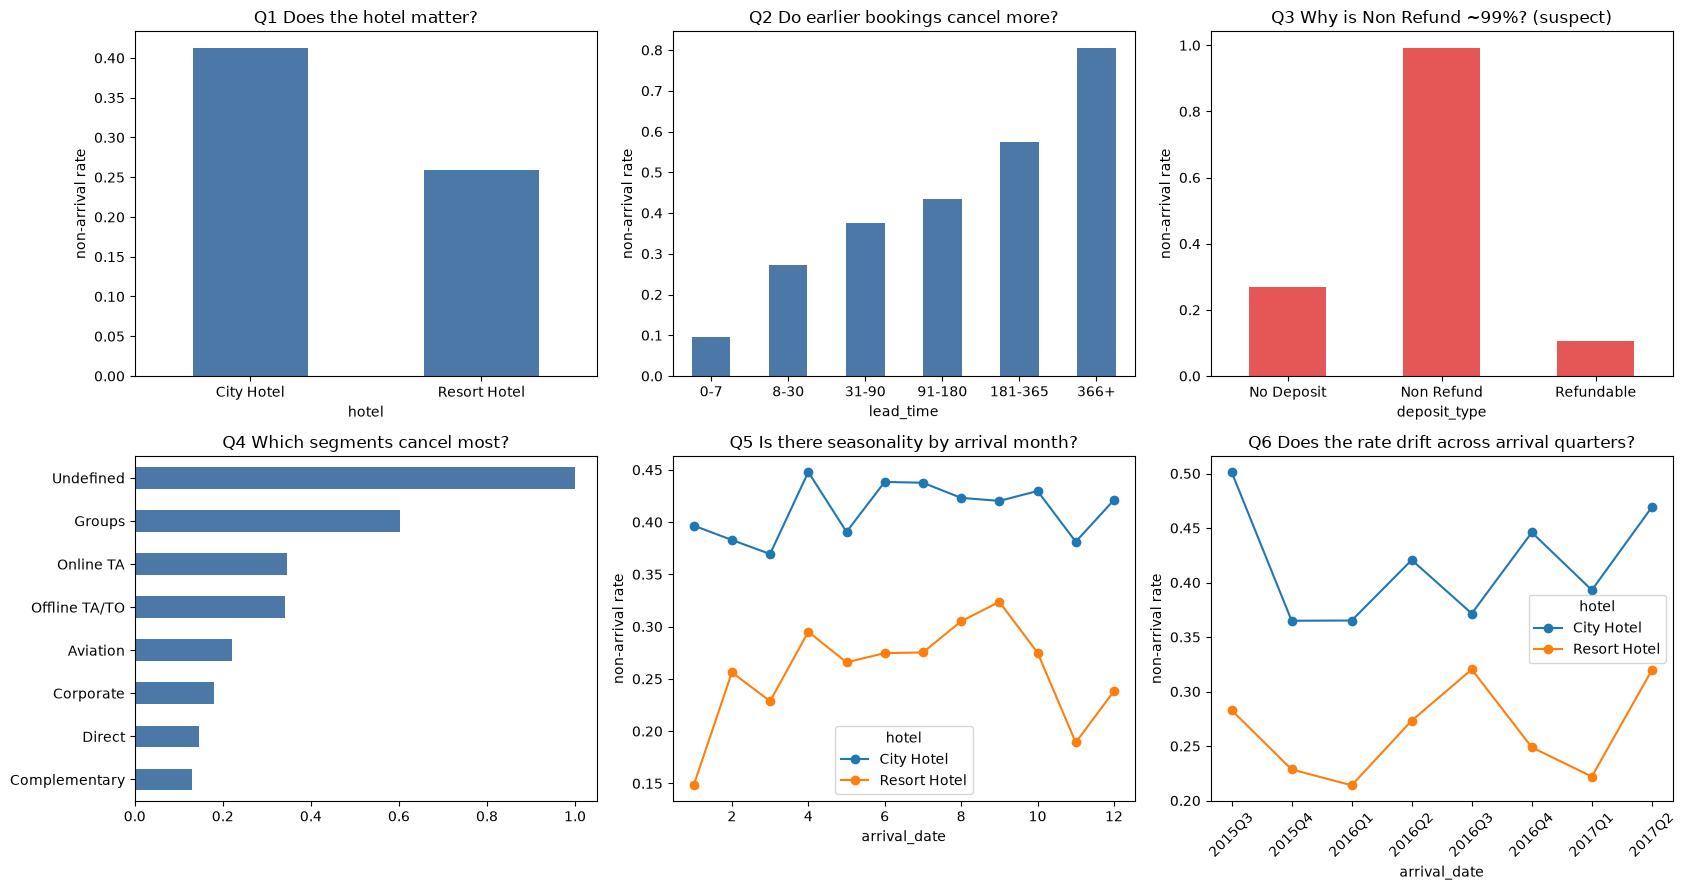

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
dev.groupby("hotel").is_canceled.mean().plot.bar(ax=ax[0, 0], color="#4C78A8", rot=0)
ax[0, 0].set_title("Q1 Does the hotel matter?")
bins = [-1, 7, 30, 90, 180, 365, 800]
lt = pd.cut(dev.lead_time, bins, labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"])
dev.groupby(lt).is_canceled.mean().plot.bar(ax=ax[0, 1], color="#4C78A8", rot=0)
ax[0, 1].set_title("Q2 Do earlier bookings cancel more?")
dev.groupby("deposit_type").is_canceled.mean().plot.bar(ax=ax[0, 2], color="#E45756", rot=0)
ax[0, 2].set_title("Q3 Why is Non Refund ~99%? (suspect)")
dev.groupby("market_segment").is_canceled.mean().sort_values().plot.barh(ax=ax[1, 0], color="#4C78A8")
ax[1, 0].set_title("Q4 Which segments cancel most?")
mo = dev.groupby([dev.arrival_date.dt.month, "hotel"]).is_canceled.mean().unstack()
mo.plot(ax=ax[1, 1], marker="o"); ax[1, 1].set_title("Q5 Is there seasonality by arrival month?")
q = dev.groupby([dev.arrival_date.dt.to_period("Q").astype(str), "hotel"]).is_canceled.mean().unstack()
q.plot(ax=ax[1, 2], marker="o", rot=45); ax[1, 2].set_title("Q6 Does the rate drift across arrival quarters?")
for a in ax.ravel():
    a.set_ylabel("non-arrival rate" if a not in (ax[1, 0],) else "")
plt.tight_layout(); plt.savefig(FIG / "02_eda_rates.png", dpi=110); plt.show()

In [8]:
tab = {}
tab["lead_time_bins"] = dev.groupby(lt).is_canceled.agg(["size", "mean"]).round(3)
tab["deposit"] = dev.groupby("deposit_type").is_canceled.agg(["size", "mean"]).round(3)
tab["segment"] = dev.groupby("market_segment").is_canceled.agg(["size", "mean"]).round(3)
tab["month"] = mo.round(3)
for k, v in tab.items():
    print("\n" + k); print(v)
M["rate_by_lead_bin"] = tab["lead_time_bins"]["mean"].to_dict()
M["rate_by_deposit"] = tab["deposit"]["mean"].to_dict()


lead_time_bins
            size   mean
lead_time              
0-7        17342  0.095
8-30       15933  0.273
31-90      25536  0.374
91-180     18801  0.434
181-365    15685  0.575
366+        2052  0.806

deposit
               size   mean
deposit_type              
No Deposit    82974  0.268
Non Refund    12235  0.992
Refundable      140  0.107

segment
                 size   mean
market_segment              
Aviation          163  0.221
Complementary     635  0.129
Corporate        4655  0.180
Direct           9950  0.145
Groups          17062  0.603
Offline TA/TO   20373  0.341
Online TA       42509  0.347
Undefined           2  1.000

month
hotel         City Hotel  Resort Hotel
arrival_date                          
1                  0.397         0.148
2                  0.383         0.256
3                  0.369         0.229
4                  0.448         0.295
5                  0.391         0.266
6                  0.438         0.275
7                  0.438      

## 2.4 Verify data quality
Missingness, invalid values, outliers, duplicates, and the `deposit_type` anomaly.

In [9]:
nights = dev.stays_in_weekend_nights + dev.stays_in_week_nights
guests = dev.adults + dev.children.fillna(0) + dev.babies
Q = {
 "missing_children": int(dev.children.isna().sum()),
 "missing_country": int(dev.country.isna().sum()),
 "missing_agent": int(dev.agent.isna().sum()),
 "missing_company": int(dev.company.isna().sum()),
 "zero_guests": int((guests == 0).sum()),
 "zero_nights": int((nights == 0).sum()),
 "adr_negative": int((dev.adr < 0).sum()),
 "adr_max": float(dev.adr.max()),
 "adr_over_1000": int((dev.adr > 1000).sum()),
 "lead_time_max": int(dev.lead_time.max()),
 "adults_over_10": int((dev.adults > 10).sum()),
 "meal_undefined": int((dev.meal == "Undefined").sum()),
 "full_row_duplicates": int(dev.duplicated().sum()),
}
print(json.dumps(Q, indent=1))
print("non-arrival rate, zero-night bookings:", round(dev[nights == 0].is_canceled.mean(), 3),
      "| zero-guest bookings:", round(dev[guests == 0].is_canceled.mean(), 3))
dup = dev.duplicated(keep=False)
print("rows in a duplicate group:", int(dup.sum()), "| non-arrival rate in duplicate groups:",
      round(dev[dup].is_canceled.mean(), 3), "vs", round(dev[~dup].is_canceled.mean(), 3))
print("duplicate groups by segment:\n", dev[dev.duplicated()].market_segment.value_counts().head(4).to_dict())

{
 "missing_children": 4,
 "missing_country": 483,
 "missing_agent": 13780,
 "missing_company": 89423,
 "zero_guests": 157,
 "zero_nights": 665,
 "adr_negative": 1,
 "adr_max": 5400.0,
 "adr_over_1000": 1,
 "lead_time_max": 737,
 "adults_over_10": 12,
 "meal_undefined": 1055,
 "full_row_duplicates": 26936
}
non-arrival rate, zero-night bookings: 0.047 | zero-guest bookings: 0.134
rows in a duplicate group: 33551 | non-arrival rate in duplicate groups: 0.579 vs 0.242
duplicate groups by segment:
 {'Groups': 12788, 'Offline TA/TO': 8928, 'Online TA': 3534, 'Corporate': 996}


**The `deposit_type` anomaly.** Non Refund bookings have a near-certain non-arrival rate. We check where they come from.

In [10]:
nr = dev[dev.deposit_type == "Non Refund"]
print("Non Refund rows:", len(nr), "| non-arrival rate:", round(nr.is_canceled.mean(), 4))
print(nr.groupby("hotel").is_canceled.agg(["size", "mean"]).round(3))
print(nr.groupby("market_segment").is_canceled.agg(["size", "mean"]).round(3))
print("share Portugal:", round((nr.country == "PRT").mean(), 3), "| share with an agent:", round(nr.agent.notna().mean(), 3))
top_ag = nr.agent.value_counts().head(5)
print("top agents among Non Refund (rows):", top_ag.to_dict(), "| their share:", round(top_ag.sum() / len(nr), 3))
other = dev[(dev.deposit_type != "Non Refund")]
print("same agents, other deposit types, non-arrival rate:",
      round(other[other.agent.isin(top_ag.index)].is_canceled.mean(), 3))
stayed = nr[nr.is_canceled == 0]
print("Non Refund that did arrive:", len(stayed), "| adr median:", stayed.adr.median(), "vs all arrivals:", dev[dev.is_canceled == 0].adr.median())
M["nonrefund_n"] = int(len(nr)); M["nonrefund_rate"] = round(float(nr.is_canceled.mean()), 4)
M["nonrefund_top5_agent_share"] = round(float(top_ag.sum() / len(nr)), 3)

Non Refund rows: 12235 | non-arrival rate: 0.9925
               size   mean
hotel                     
City Hotel    10627  0.998
Resort Hotel   1608  0.958
                size   mean
market_segment             
Corporate        299  0.926
Direct            13  0.769
Groups          7631  0.992
Offline TA/TO   4241  0.999
Online TA         51  0.961
share Portugal: 0.967 | share with an agent: 0.891
top agents among Non Refund (rows): {1.0: 4052, 6.0: 572, 3.0: 543, 19.0: 538, 37.0: 509} | their share: 0.508
same agents, other deposit types, non-arrival rate: 0.264
Non Refund that did arrive: 92 | adr median: 79.91499999999999 vs all arrivals: 86.69


**Leakage audit evidence.** For each Set B field we look at how differently it is distributed for arrivals and non-arrivals.

In [11]:
aud = pd.DataFrame({
  "room_changed_rate": (dev.assigned_room_type != dev.reserved_room_type).groupby(dev.is_canceled).mean(),
  "mean_booking_changes": dev.groupby("is_canceled").booking_changes.mean(),
  "share_parking_required": (dev.required_car_parking_spaces > 0).groupby(dev.is_canceled).mean(),
  "mean_special_requests": dev.groupby("is_canceled").total_of_special_requests.mean(),
  "mean_waiting_days": dev.groupby("is_canceled").days_in_waiting_list.mean(),
  "mean_adr": dev.groupby("is_canceled").adr.mean(),
}).round(3)
print(aud)
M["audit"] = aud.to_dict()
print("country missing share, arrivals vs non-arrivals:", dev.country.isna().groupby(dev.is_canceled).mean().round(4).to_dict())

             room_changed_rate  mean_booking_changes  share_parking_required  mean_special_requests  mean_waiting_days  mean_adr
is_canceled                                                                                                                     
0                         0.21                 0.284                   0.101                  0.672              1.937    92.368
1                         0.02                 0.093                   0.000                  0.288              4.492    95.640
country missing share, arrivals vs non-arrivals: {0: 0.0069, 1: 0.0018}


In [12]:
json.dump({"M": M, "Q": Q}, open(ART / "metrics_phase2.json", "w"), indent=1, default=str)

# Phase 3: Data Preparation
## 3.1 Select data
Rationale per group:
- **Excluded:** `reservation_status`, `reservation_status_date` (they encode the outcome). They are used only to work out when an outcome became known.
- **Set A (deployed model):** fields normally fixed when the booking is made.
- **Set B (diagnostic only):** fields not shown to be known at booking (`country`, `assigned_room_type`, `booking_changes`, `days_in_waiting_list`, `adr`, `required_car_parking_spaces`, `total_of_special_requests`) and `deposit_type`.
- `arrival_date_year` is used only to order rows in time. It is not a feature, since a test year would be unseen.
- Rows: all rows are in scope except the invalid records removed below.

## 3.2 Clean data (every rule with its row count)

In [13]:
df = raw.copy()
rules = []
def apply_rule(name, bad, action):
    global df
    bad = bad.reindex(df.index, fill_value=False)
    rules.append({"rule": name, "rows_affected": int(bad.sum()), "action": action})
    if action.startswith("drop"):
        df = df[~bad]
n_before = len(df)
guests = df.adults + df.children.fillna(0) + df.babies
apply_rule("zero guests (adults+children+babies = 0)", guests == 0, "drop (not a real stay)")
apply_rule("adr < 0", df.adr < 0, "drop (invalid price)")
apply_rule("adr > 1000 (single record of 5400)", df.adr > 1000, "drop (extreme outlier)")
apply_rule("children missing", df.children.isna(), "impute 0 inside pipeline")
apply_rule("meal = Undefined", df.meal == "Undefined", "merge into SC inside pipeline (same meaning per source)")
apply_rule("market_segment or distribution_channel = Undefined", (df.market_segment == "Undefined") | (df.distribution_channel == "Undefined"), "keep as its own category")
apply_rule("zero nights (day-use or stay not recorded)", (df.stays_in_weekend_nights + df.stays_in_week_nights) == 0, "keep, flag `zero_nights`")
apply_rule("full-row duplicates (all 32 columns)", df.duplicated(), "keep (may be group bookings); sensitivity run in Phase 4")
rep = pd.DataFrame(rules); display(rep)
print("rows before:", n_before, "| after:", len(df), "| removed:", n_before - len(df))
rep.to_csv(ART / "cleaning_report.csv", index=False)

,rule,rows_affected,action
0,zero guests (adults+children+babies = 0),180,drop (not a real stay)
1,adr < 0,1,drop (invalid price)
2,adr > 1000 (single record of 5400),1,drop (extreme outlier)
3,children missing,4,impute 0 inside pipeline
4,meal = Undefined,1169,merge into SC inside pipeline (same meaning pe...
5,market_segment or distribution_channel = Undef...,5,keep as its own category
6,zero nights (day-use or stay not recorded),645,"keep, flag `zero_nights`"
7,full-row duplicates (all 32 columns),31980,keep (may be group bookings); sensitivity run ...


rows before: 119390 | after: 119208 | removed: 182


## 3.3 Construct data, 3.4 Integrate data
Derived attributes are built in `hotel_features.add_features` so training and serving use the same code:
`total_nights`, `zero_nights`, `total_guests`, `has_children`, `log_lead_time`, `arrival_weekday`, `has_agent`, `has_company`, `agent_id`, `room_changed` (Set B only).
Seasonality is carried by the arrival month and week number.
**Integrate:** the source is a single table, so no joins were needed.

In [14]:
show = hf.add_features(df.head(3)[hf.RAW_A_COLS])
display(show[["total_nights", "total_guests", "log_lead_time", "arrival_weekday", "has_agent", "agent_id"]])

,total_nights,total_guests,log_lead_time,arrival_weekday,has_agent,agent_id
0,0,2.0,5.837730,2,0,none
1,0,2.0,6.603944,2,0,none
2,1,1.0,2.079442,2,0,none


## 3.5 Time-based design and split
**Amendment to the Phase 1 protocol.** Phase 1 said to order bookings by derived booking date. Phase 2 showed why that is a poor choice here: the file contains only bookings *due to arrive* between 2015-07-01 and 2017-08-31, so the last booking dates miss every long-lead booking (right-censoring), and a training booking made before a cut can have its outcome decided after the cut.
We therefore order rows by **arrival date**. A model trained on stays that arrived before a cut date only uses outcomes that were known by then, and it is tested on all bookings that arrive afterwards.

Layout (fractions of rows, ordered by arrival date): fit 0-60%, calibration 60-70%, threshold selection 70-80%, **final test 80-100% (opened once, in Phase 5)**. Model comparison uses expanding-window folds inside the first 80%.

In [15]:
df = df.sort_values("arrival_date", kind="mergesort").reset_index(drop=True)
n = len(df)
cut = {q: df.arrival_date.iloc[int(n * q)] for q in (0.4, 0.5, 0.6, 0.7)}
cut[0.8] = TEST_START  # fixed in Phase 2 by date, before any outcome was inspected
def seg(lo, hi):
    m = pd.Series(True, index=df.index)
    if lo is not None: m &= df.arrival_date >= cut[lo]
    if hi is not None: m &= df.arrival_date < cut[hi]
    return m
S = {"fit": seg(None, 0.6), "cal": seg(0.6, 0.7), "val": seg(0.7, 0.8), "test": seg(0.8, None)}
FOLDS = [(seg(None, a), seg(a, b)) for a, b in [(0.4, 0.5), (0.5, 0.6), (0.6, 0.7), (0.7, 0.8)]]
rows = []
for k, m in S.items():
    rows.append({"segment": k, "rows": int(m.sum()), "from": df.arrival_date[m].min().date(), "to": df.arrival_date[m].max().date(),
                 "non_arrival_rate": (round(df.is_canceled[m].mean(), 4) if k != "test" else "sealed")})
split_tab = pd.DataFrame(rows); display(split_tab)
split_tab.to_csv(ART / "split_summary.csv", index=False)
print("cut dates:", {k: str(v.date()) for k, v in cut.items()})
print("months present in test:", sorted(df.arrival_date[S['test']].dt.month.unique()))

,segment,rows,from,to,non_arrival_rate
0,fit,71465,2015-07-01,2016-11-06,0.3638
1,cal,11854,2016-11-07,2017-02-09,0.3408
2,val,11871,2017-02-10,2017-04-21,0.3634
3,test,24018,2017-04-22,2017-08-31,sealed


cut dates: {0.4: '2016-06-21', 0.5: '2016-09-06', 0.6: '2016-11-07', 0.7: '2017-02-10', 0.8: '2017-04-22'}
months present in test: [np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8)]


**Duplicate / twin rule.** The split is by date, one row at a time, so no test row enters training. We count test rows that have an identical twin before the test period, using two keys:
(a) every Set A field, and (b) a *profile* key that drops the arrival date fields. The target is deliberately left out of both keys (Phase 1 had said Set A plus target), so the subset is defined without any test label.
Results in Phase 5 are reported on all test rows and on test rows without a profile twin.

In [16]:
from pandas.util import hash_pandas_object
pre = S["fit"] | S["cal"] | S["val"]
keyA = hash_pandas_object(df[hf.RAW_A_COLS], index=False)  # target left out so that no test label is used
date_cols = ["arrival_date_year", "arrival_date_month", "arrival_date_week_number", "arrival_date_day_of_month"]
keyP = hash_pandas_object(df[[c for c in hf.RAW_A_COLS if c not in date_cols]], index=False)
twinA = S["test"] & keyA.isin(set(keyA[pre]))
twinP = S["test"] & keyP.isin(set(keyP[pre]))
df["test_profile_twin"] = twinP
TW = {"test_rows": int(S["test"].sum()), "exact_twin_in_pre_test": int(twinA.sum()),
      "profile_twin_in_pre_test": int(twinP.sum()),
      "profile_twin_share": round(twinP.sum() / S["test"].sum(), 3)}
print(TW)

{'test_rows': 24018, 'exact_twin_in_pre_test': 0, 'profile_twin_in_pre_test': 4887, 'profile_twin_share': np.float64(0.203)}


## 3.6 Format data: one scikit-learn pipeline, fit on training data only
The pipeline does feature construction, median imputation, clipping at the 99.9th training percentile, scaling, and one-hot encoding with rare categories grouped, then the classifier.
**Outlier decision:** `lead_time`, nights, adults, parking, waiting days and similar counts have long right tails. Genuine extremes (a 737-day lead time, a 55-person group) are real events, so rows are kept and the *values* are clipped at the 99.9th percentile of the training segment. `log_lead_time` is added for the linear model.

In [17]:
from sklearn.linear_model import LogisticRegression
X_cols = hf.RAW_A_COLS + hf.RAW_B_COLS + ["deposit_type"]
X, y = df[X_cols], df["is_canceled"].astype(int)
lr_demo = hf.build_pipeline(LogisticRegression(max_iter=300), hf.NUM_A, hf.CAT_A)
lr_demo.fit(X[S["fit"]], y[S["fit"]])
Xt = lr_demo[:-1].transform(X[S["fit"]])
print("transformed fit shape:", Xt.shape)
sc = lr_demo.named_steps["pre"].named_transformers_["num"]
j = hf.NUM_A.index("lead_time")
clip_hi = sc.named_steps["clip"].hi_[j]
print("lead_time: clip at", clip_hi, "| fit-only mean after clipping:", round(sc.named_steps["sc"].mean_[j], 2),
      "| full-data mean:", round(df.lead_time.mean(), 2))
# by-hand recomputation of the same statistic
manual = np.clip(df.lead_time[S["fit"]], None, df.lead_time[S["fit"]].quantile(0.999)).mean()
print("by hand:", round(manual, 2), "| matches:", np.isclose(manual, sc.named_steps["sc"].mean_[j]))

out = pd.DataFrame([{"column": c, "n_clipped_in_fit": int((df.loc[S['fit'], c] > df.loc[S['fit'], c].quantile(.999)).sum()),
                     "clip_value": float(df.loc[S['fit'], c].quantile(.999)), "max": float(df[c].max())}
                    for c in ["lead_time", "stays_in_week_nights", "stays_in_weekend_nights", "adults", "previous_cancellations", "previous_bookings_not_canceled"]])
display(out)

transformed fit shape: (71465, 109)
lead_time: clip at 482.0 | fit-only mean after clipping: 102.76 | full-data mean: 104.11
by hand: 102.76 | matches: True


,column,n_clipped_in_fit,clip_value,max
0,lead_time,56,482.000,737.0
1,stays_in_week_nights,62,15.000,50.0
2,stays_in_weekend_nights,60,6.000,19.0
3,adults,52,3.000,55.0
4,previous_cancellations,51,24.000,26.0
5,previous_bookings_not_canceled,72,19.536,72.0


**Leakage tests** (these must pass before modeling).

In [18]:
fit_pre = S["fit"] | S["cal"] | S["val"]
assert df.arrival_date[fit_pre].max() < df.arrival_date[S["test"]].min(), "test period overlaps training period"
for a, b in [("fit", "cal"), ("cal", "val"), ("val", "test")]:
    assert df.arrival_date[S[a]].max() < df.arrival_date[S[b]].min()
assert not ({"is_canceled", "reservation_status", "reservation_status_date", "deposit_type"} & set(hf.NUM_A + hf.CAT_A))
assert set(hf.RAW_A_COLS).isdisjoint({"reservation_status", "reservation_status_date", "is_canceled"})
for tr, va in FOLDS:
    assert df.arrival_date[tr].max() < df.arrival_date[va].min()
print("all leakage and ordering checks passed")

all leakage and ordering checks passed


## 3.7 Output: final dataset and description

In [19]:
final = df[hf.RAW_A_COLS + hf.RAW_B_COLS + ["deposit_type", "is_canceled", "arrival_date"]].copy()
final["segment"] = np.select([S["fit"], S["cal"], S["val"], S["test"]], ["fit", "cal", "val", "test"], default="none")
final.to_csv(DATA / "hotel_prepared.csv.gz", index=False)
schema = pd.DataFrame({"column": final.columns, "dtype": final.dtypes.astype(str).values,
                       "role": ["input only (date order, weekday)" if c == "arrival_date_year" else "Set A" if c in hf.RAW_A_COLS else "Set B" if c in hf.RAW_B_COLS else "Set B (flagged)" if c == "deposit_type"
                                else "target" if c == "is_canceled" else "bookkeeping" for c in final.columns]})
schema.to_csv(ART / "final_dataset_schema.csv", index=False); display(schema)
desc = {"rows": len(final), "columns": final.shape[1], "set_A_raw_columns": len(hf.RAW_A_COLS),
        "set_A_model_features": len(hf.NUM_A) + len(hf.CAT_A), "set_B_raw_columns": len(hf.RAW_B_COLS),
        "target_rate_dev": round(final.is_canceled[final.segment != "test"].mean(), 4), "rows_removed": n_before - len(final)}
print(desc)
json.dump({"cleaning": rules, "split": split_tab.astype(str).to_dict("records"), "twins": TW, "desc": desc,
           "cut_dates": {str(k): str(v.date()) for k, v in cut.items()}},
          open(ART / "metrics_phase3.json", "w"), indent=1, default=str)

,column,dtype,role
0,hotel,str,Set A
1,lead_time,int64,Set A
2,arrival_date_year,int64,"input only (date order, weekday)"
3,arrival_date_month,str,Set A
4,arrival_date_week_number,int64,Set A
5,arrival_date_day_of_month,int64,Set A
6,stays_in_weekend_nights,int64,Set A
7,stays_in_week_nights,int64,Set A
8,adults,int64,Set A
9,children,float64,Set A


{'rows': 119208, 'columns': 32, 'set_A_raw_columns': 21, 'set_A_model_features': 27, 'set_B_raw_columns': 7, 'target_rate_dev': np.float64(0.3609), 'rows_removed': 182}


# Phase 4: Modeling
**The test period stays sealed.** Everything here uses the fit, calibration and validation segments and rolling folds inside them.
## 4.1 Select modeling techniques
| Technique | Why | Assumptions / needs |
|---|---|---|
| Majority (prior) baseline | Floor for every metric | none |
| Logistic regression | Interpretable, calibrated by construction | Roughly linear log-odds; scaled inputs; handles one-hot features |
| Decision tree (depth-limited) | Readable rules, captures interactions | Depth limit to avoid overfitting |
| LightGBM boosted trees | Strong on tabular data with mixed types and interactions | Needs tuning; probabilities need calibration |
| k-means on the prepared features | Guest segments (optional, used only if it helps) | Spherical clusters in scaled space |

## 4.2 Generate test design
Expanding-window folds by arrival date inside the first 80% (train up to the cut, validate on the next 10% of rows). Final design: **fit** 0-60%, **calibrate** (isotonic) 60-70%, **choose the threshold** 70-80%. The test (80-100%) is untouched until Phase 5.
Primary metric: net benefit of the capped policy (Phase 1 cost model). Supporting: PR-AUC, ROC-AUC, Brier score.

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
import lightgbm as lgb, time, joblib, hashlib, datetime

def mk_lgb(**kw):
    p = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
             colsample_bytree=0.8, random_state=SEED, n_jobs=4, verbose=-1)
    p.update(kw); return lgb.LGBMClassifier(**p)

NUM_A1 = [c for c in hf.NUM_A if c not in ("is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled")]
SETS = {"A1 (reservation request only)": (NUM_A1, hf.CAT_A),
        "A (A1 + history counters)": (hf.NUM_A, hf.CAT_A),
        "A + deposit_type": (hf.NUM_A, hf.CAT_A + hf.CAT_DEP),
        "A + B": (hf.NUM_A + hf.NUM_B, hf.CAT_A + hf.CAT_B),
        "A + B + deposit_type": (hf.NUM_A + hf.NUM_B, hf.CAT_A + hf.CAT_B + hf.CAT_DEP)}
NUM, CAT = SETS["A (A1 + history counters)"]

def metrics(yt, p):
    return {"pr_auc": average_precision_score(yt, p), "roc_auc": roc_auc_score(yt, p), "brier": brier_score_loss(yt, p)}

def cv_table(make_model, num, cat, extra=None):
    rows = []
    for k, (tr, va) in enumerate(FOLDS, 1):
        pipe = hf.build_pipeline(make_model(), num, cat).fit(X[tr], y[tr])
        p = pipe.predict_proba(X[va])[:, 1]
        m = metrics(y[va], p)
        f, _ = capped_flags(p, WEEK[va.values], ARR[va.values], THR_CLOSED)
        m["net_benefit_per_1000"] = net_benefit(y[va].values, f) / int(va.sum()) * 1000
        rows.append({"fold": k, "train_rows": int(tr.sum()), "val_rows": int(va.sum()), **m})
    return pd.DataFrame(rows)

def summ(t): return f'{t.pr_auc.mean():.4f} +/- {t.pr_auc.std():.4f}'

**Policy functions** (Phase 1 cost model and weekly rank cap), defined first so that every comparison below can report net benefit, the primary metric.

In [21]:
CAP, S_RATE, C_COST, L_LOSS = 0.25, 0.25, 20.0, 150.0
iso = df.arrival_date.dt.isocalendar()
WEEK = (iso.year.astype(int) * 100 + iso.week.astype(int)).values
ARR = df.arrival_date.values.astype("datetime64[D]").astype(int)

def capped_flags(score, week, arr, thr, cap=CAP):
    n = len(score); order = np.lexsort((np.arange(n), arr, -score, week))
    ws = week[order]; starts = np.r_[True, ws[1:] != ws[:-1]]; grp = np.cumsum(starts) - 1
    rank = np.arange(n) - np.flatnonzero(starts)[grp]; size = np.bincount(grp)[grp]
    allowed = rank < np.floor(cap * size); passes = score[order] >= thr
    flags = np.zeros(n, bool); flags[order] = passes & allowed
    n_pass = np.bincount(grp, weights=passes.astype(float)); cap_n = np.floor(cap * np.bincount(grp))
    return flags, float((n_pass > cap_n).mean())

def net_benefit(yt, flags, s=S_RATE, c=C_COST, L=L_LOSS):
    return float((flags * (s * L * np.asarray(yt) - c)).sum())

def policy_report(yt, score, week, arr, thr):
    f, binds = capped_flags(score, week, arr, thr); yt = np.asarray(yt)
    return {"flagged_share": f.mean(), "precision": float(yt[f].mean()) if f.any() else np.nan,
            "recall": float(f[yt == 1].mean()), "net_benefit_per_1000": net_benefit(yt, f) / len(yt) * 1000, "cap_binds_share_of_weeks": binds}

def cal_slope(yt, p):
    q = np.clip(p, 1e-4, 1 - 1e-4); z = np.log(q / (1 - q))
    return float(LogisticRegression(C=1e9, max_iter=500).fit(z.reshape(-1, 1), yt).coef_[0, 0])

THR_CLOSED = C_COST / (S_RATE * L_LOSS)  # 0.533, the uncapped break-even probability

## 4.3 Build models: baselines and default parameters
Net benefit in the fold tables uses the fixed closed-form threshold 0.533 and the weekly cap on uncalibrated probabilities, so no threshold is tuned inside the folds.

In [22]:
t0 = time.time()
cv = {}
cv["Majority (prior)"] = cv_table(lambda: DummyClassifier(strategy="prior"), NUM, CAT)
cv["Logistic regression (C=1)"] = cv_table(lambda: LogisticRegression(max_iter=500), NUM, CAT)
cv["Decision tree (depth 8)"] = cv_table(lambda: DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=SEED), NUM, CAT)
cv["LightGBM (default params)"] = cv_table(mk_lgb, NUM, CAT)
tab = pd.DataFrame({k: {"PR-AUC mean": v.pr_auc.mean(), "PR-AUC sd": v.pr_auc.std(), "ROC-AUC": v.roc_auc.mean(), "Brier": v.brier.mean(), "NB/1000 mean": v.net_benefit_per_1000.mean(), "NB/1000 sd": v.net_benefit_per_1000.std()} for k, v in cv.items()}).T.round(4)
display(tab); print("seconds:", round(time.time() - t0))
display(cv["LightGBM (default params)"].round(4))

,PR-AUC mean,PR-AUC sd,ROC-AUC,Brier,NB/1000 mean,NB/1000 sd
Majority (prior),0.3623,0.0287,0.5000,0.2312,0.0000,0.0000
Logistic regression (C=1),0.7096,0.0560,0.7866,0.1763,1363.7572,601.2439
Decision tree (depth 8),0.6387,0.0430,0.7394,0.1868,1208.0480,448.8526
LightGBM (default params),0.7134,0.0627,0.7877,0.1768,1468.3039,666.8067


seconds: 17


,fold,train_rows,val_rows,pr_auc,roc_auc,brier,net_benefit_per_1000
0,1,47557,12027,0.6196,0.7330,0.1934,526.1079
1,2,59584,11881,0.7503,0.7750,0.1916,2085.0518
2,3,71465,11854,0.7375,0.8269,0.1605,1550.9533
3,4,83319,11871,0.7461,0.8160,0.1618,1711.1027


## 4.4 Assess model and revise parameters
Six LightGBM configurations are compared on the same rolling folds. The best by mean PR-AUC is chosen. Nothing is tuned on the validation segment or the test.

In [23]:
grid = [dict(num_leaves=15, min_child_samples=100, learning_rate=0.05, n_estimators=300),
        dict(num_leaves=31, min_child_samples=50, learning_rate=0.05, n_estimators=300),
        dict(num_leaves=31, min_child_samples=100, learning_rate=0.03, n_estimators=500),
        dict(num_leaves=63, min_child_samples=50, learning_rate=0.03, n_estimators=400),
        dict(num_leaves=15, min_child_samples=50, learning_rate=0.10, n_estimators=200),
        dict(num_leaves=31, min_child_samples=200, learning_rate=0.05, n_estimators=300)]
res = []
for g in grid:
    t = cv_table(lambda: mk_lgb(**g), NUM, CAT)
    res.append({**g, "pr_auc_mean": t.pr_auc.mean(), "pr_auc_sd": t.pr_auc.std(), "brier": t.brier.mean()})
res = pd.DataFrame(res).round(4); display(res)
BEST = grid[int(res.pr_auc_mean.idxmax())]
print("chosen parameters:", BEST)
cv["LightGBM (tuned)"] = cv_table(lambda: mk_lgb(**BEST), NUM, CAT)
res.to_csv(ART / "lgbm_grid.csv", index=False)

,num_leaves,min_child_samples,learning_rate,n_estimators,pr_auc_mean,pr_auc_sd,brier
0,15,100,0.05,300,0.7187,0.0590,0.1726
1,31,50,0.05,300,0.7134,0.0627,0.1768
2,31,100,0.03,500,0.7133,0.0614,0.1762
3,63,50,0.03,400,0.7058,0.0601,0.1812
4,15,50,0.10,200,0.7126,0.0621,0.1757
5,31,200,0.05,300,0.7163,0.0658,0.1752


chosen parameters: {'num_leaves': 15, 'min_child_samples': 100, 'learning_rate': 0.05, 'n_estimators': 300}


,PR-AUC mean,PR-AUC sd,ROC-AUC,Brier,NB/1000 mean,NB/1000 sd
Majority (prior),0.3623,0.0287,0.5000,0.2312,0.0000,0.0000
Logistic regression (C=1),0.7096,0.0560,0.7866,0.1763,1363.7572,601.2439
Decision tree (depth 8),0.6387,0.0430,0.7394,0.1868,1208.0480,448.8526
LightGBM (default params),0.7134,0.0627,0.7877,0.1768,1468.3039,666.8067
LightGBM (tuned),0.7187,0.0590,0.7922,0.1726,1576.0824,518.8162


train_rows  val_rows  pr_auc  roc_auc   brier  net_benefit_per_1000
model                     fold                                                                     
Majority (prior)          1          47557     12027  0.3425   0.5000  0.2255                0.0000
                          2          59584     11881  0.4024   0.5000  0.2426                0.0000
                          3          71465     11854  0.3408   0.5000  0.2252                0.0000
                          4          83319     11871  0.3634   0.5000  0.2314                0.0000
Logistic regression (C=1) 1          47557     12027  0.6280   0.7355  0.1862              579.9451
                          2          59584     11881  0.7543   0.7903  0.1878             1835.7041
                          3          71465     11854  0.7214   0.8229  0.1613             1204.4458
                          4          83319     11871  0.7345   0.7976  0.1697             1834.9339
Decision tree (depth 8)   1          47557     12027  0.5760   0.6990  0.1971              598.0294
                          2          59584     11881  0.6598   0.7417  0.1992             1657.6887
                          3          71465     11854  0.6473   0.7632  0.1708             1195.3771
                          4          83319     11871  0.6717   0.7538  0.1800             1381.0968
LightGBM (default params) 1          47557     12027  0.6196   0.7330  0.1934              526.1079
                          2          59584     11881  0.7503   0.7750  0.1916             2085.0518
                          3          71465     11854  0.7375   0.8269  0.1605             1550.9533
                          4          83319     11871  0.7461   0.8160  0.1618             1711.1027
LightGBM (tuned)          1          47557     12027  0.6307   0.7388  0.1834              875.3222
                          2          59584     11881  0.7562   0.7839  0.1877             2091.1539
                          3          71465     11854  0.7429   0.8308  0.1574             1538.7211
                          4          83319     11871  0.7450   0.8152  0.1618             1799.1323

D1 (rolling CV): LightGBM minus LR PR-AUC = 0.0091 vs LR fold sd 0.0560 -> FAIL
supplementary paired difference per fold (LightGBM - LR): [0.0026, 0.0019, 0.0215, 0.0105] | mean 0.0091 | sd 0.0091


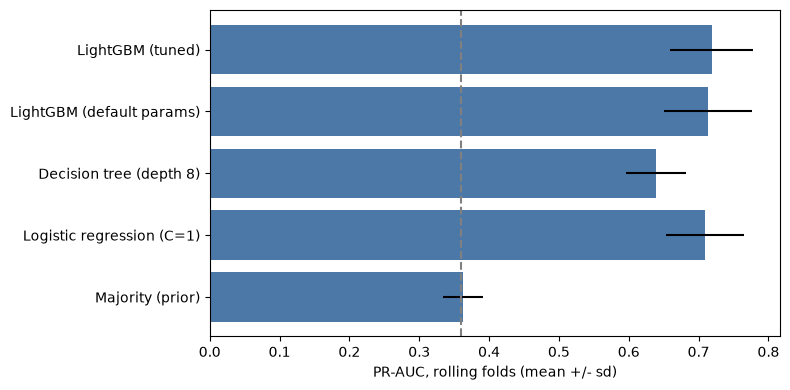

In [24]:
tab = pd.DataFrame({k: {"PR-AUC mean": v.pr_auc.mean(), "PR-AUC sd": v.pr_auc.std(), "ROC-AUC": v.roc_auc.mean(), "Brier": v.brier.mean(), "NB/1000 mean": v.net_benefit_per_1000.mean(), "NB/1000 sd": v.net_benefit_per_1000.std()} for k, v in cv.items()}).T.round(4)
display(tab); tab.to_csv(ART / "model_comparison_cv.csv")
allf = pd.concat({k: v.set_index("fold") for k, v in cv.items()}, names=["model"]).round(4); allf.to_csv(ART / "cv_folds_all.csv")
display(allf[["train_rows", "val_rows", "pr_auc", "roc_auc", "brier", "net_benefit_per_1000"]])
d1 = cv["LightGBM (tuned)"].pr_auc.mean() - cv["Logistic regression (C=1)"].pr_auc.mean()
d1_sd = cv["Logistic regression (C=1)"].pr_auc.std()
print(f"D1 (rolling CV): LightGBM minus LR PR-AUC = {d1:.4f} vs LR fold sd {d1_sd:.4f} -> {'PASS' if d1 > d1_sd else 'FAIL'}")
paired = cv["LightGBM (tuned)"].pr_auc - cv["Logistic regression (C=1)"].pr_auc
print("supplementary paired difference per fold (LightGBM - LR):", paired.round(4).tolist(), "| mean", round(paired.mean(), 4), "| sd", round(paired.std(), 4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(tab.index, tab["PR-AUC mean"], xerr=tab["PR-AUC sd"], color="#4C78A8"); ax.set_xlabel("PR-AUC, rolling folds (mean +/- sd)")
ax.axvline(0.36, color="grey", ls="--"); plt.tight_layout(); plt.savefig(FIG / "04_model_comparison.png", dpi=110); plt.show()

## 4.5 Feature sets: what do Set B and `deposit_type` add? (criterion D5, validation version)
Same tuned LightGBM, rolling folds. "Gap" = PR-AUC(set) minus PR-AUC(Set A).

In [25]:
rows = []
for name, (nu, ca) in SETS.items():
    t = cv_table(lambda: mk_lgb(**BEST), nu, ca)
    rows.append({"feature set": name, "PR-AUC mean": t.pr_auc.mean(), "PR-AUC sd": t.pr_auc.std(), "Brier": t.brier.mean()})
sets_tab = pd.DataFrame(rows).set_index("feature set")
sets_tab["gap vs A"] = sets_tab["PR-AUC mean"] - sets_tab.loc["A (A1 + history counters)", "PR-AUC mean"]
display(sets_tab.round(4)); sets_tab.round(4).to_csv(ART / "feature_set_comparison.csv")

,PR-AUC mean,PR-AUC sd,Brier,gap vs A
feature set,,,,
A1 (reservation request only),0.6921,0.0743,0.1825,-0.0266
A (A1 + history counters),0.7187,0.0590,0.1726,0.0000
A + deposit_type,0.7480,0.0657,0.1644,0.0293
A + B,0.8445,0.0545,0.1398,0.1258
A + B + deposit_type,0.8518,0.0464,0.1403,0.1331


## 4.6 Robustness checks (fit segment to validation segment)
1. Remove full-row duplicates from the fit segment. 2. Cancellation-only target (no-shows counted as arrivals). 3. A1 versus A (above).

In [26]:
def fit_val(mask_fit, target, num=NUM, cat=CAT, mask_val=None):
    mask_val = S["val"] if mask_val is None else mask_val
    pipe = hf.build_pipeline(mk_lgb(**BEST), num, cat).fit(X[mask_fit], target[mask_fit])
    return average_precision_score(target[mask_val], pipe.predict_proba(X[mask_val])[:, 1])
dupcols = hf.RAW_A_COLS + hf.RAW_B_COLS + ["deposit_type", "is_canceled"]
dup_row = df.duplicated(subset=dupcols, keep="first")
fit_nodup = S["fit"] & ~dup_row
y_cancel = (df.reservation_status == "Canceled").astype(int)
rob = pd.DataFrame([
    {"check": "main (fit, with duplicates)", "rows_fit": int(S["fit"].sum()), "val PR-AUC": fit_val(S["fit"], y)},
    {"check": "duplicates removed from fit", "rows_fit": int(fit_nodup.sum()), "val PR-AUC": fit_val(fit_nodup, y)},
    {"check": "cancellation-only target (val labelled the same way)", "rows_fit": int(S["fit"].sum()), "val PR-AUC": fit_val(S["fit"], y_cancel)},
]).round(4)
display(rob); rob.to_csv(ART / "robustness_phase4.csv", index=False)

,check,rows_fit,val PR-AUC
0,"main (fit, with duplicates)",71465,0.7381
1,duplicates removed from fit,49673,0.6978
2,cancellation-only target (val labelled the sam...,71465,0.7393


## 4.7 Cluster guests into segments (optional)
k-means on the prepared Set A matrix, fit on the fit segment only. A cluster is kept only if it adds predictive value or a clear, actionable group.

silhouette by k: {2: 0.202, 3: 0.29, 4: 0.171, 5: 0.106, 6: 0.116, 7: 0.124}


n       non_arrival         lead      
seg        fit   val         fit    val   fit   val
cluster                                            
0         5044   855       0.310  0.377  49.0  55.0
1        58223  9107       0.396  0.386  82.0  66.0
2         8198  1909       0.170  0.251   4.0   9.0

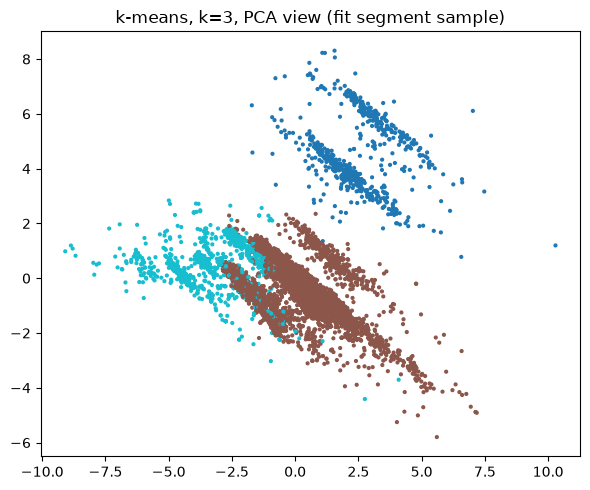

tuned LightGBM PR-AUC, without cluster: 0.7187 +/- 0.0590 | with cluster feature: 0.7168 +/- 0.0607
use cluster feature: False


In [27]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
base_pipe = hf.build_pipeline(LogisticRegression(max_iter=500), NUM, CAT).fit(X[S["fit"]], y[S["fit"]])
prep = base_pipe[:-1]
Zfit = prep.transform(X[S["fit"]])
rng = np.random.RandomState(SEED); samp = rng.choice(len(Zfit), 8000, replace=False)
sil = {k: round(silhouette_score(Zfit[samp], KMeans(k, n_init=3, random_state=SEED).fit_predict(Zfit[samp])), 3) for k in range(2, 8)}
print("silhouette by k:", sil)
K = max(sil, key=sil.get); km = KMeans(K, n_init=10, random_state=SEED).fit(Zfit)
df["cluster"] = km.predict(prep.transform(X)).astype(str)
X = df[X_cols + ["cluster"]]
prof = df[S["fit"] | S["val"]].assign(seg=lambda d: np.where(S["fit"][d.index], "fit", "val")).groupby(["cluster", "seg"]).agg(
    n=("is_canceled", "size"), non_arrival=("is_canceled", "mean"), lead=("lead_time", "median")).round(3).unstack()
display(prof)
pca = PCA(2, random_state=SEED).fit(Zfit[samp]); P = pca.transform(Zfit[samp])
fig, ax = plt.subplots(figsize=(6, 5)); sc_ = ax.scatter(P[:, 0], P[:, 1], c=km.labels_[samp], s=4, cmap="tab10")
ax.set_title(f"k-means, k={K}, PCA view (fit segment sample)"); plt.tight_layout(); plt.savefig(FIG / "04_clusters.png", dpi=110); plt.show()
withc = cv_table(lambda: mk_lgb(**BEST), NUM, CAT + ["cluster"])
print("tuned LightGBM PR-AUC, without cluster:", summ(cv["LightGBM (tuned)"]), "| with cluster feature:", summ(withc))
USE_CLUSTER = withc.pr_auc.mean() - cv["LightGBM (tuned)"].pr_auc.mean() > cv["LightGBM (tuned)"].pr_auc.std()
print("use cluster feature:", USE_CLUSTER)

## 4.8 Final candidates, calibration, threshold (all before the test is opened)
Two candidates, logistic regression and tuned LightGBM, are each fit on the fit segment. For each, the calibration method (none, sigmoid, isotonic; fitted on the calibration segment) is chosen by Brier score on the validation segment, and the threshold is chosen on the validation segment under the Phase 1 capped policy.
**Choice rule, fixed before looking at the logistic regression result:** take LightGBM only if its validation net benefit is more than 5% higher than logistic regression's. Otherwise take logistic regression (parsimony, since D1 asks for a clear gain from the boosted model).

In [28]:
sv = S["val"].values
yv, wv, av = y[S["val"]].values, WEEK[sv], ARR[sv]
base_brier = brier_score_loss(yv, np.full(len(yv), y[S["fit"]].mean()))
grid_thr = np.round(np.arange(0.05, 0.96, 0.01), 2)

def build_candidate(name, est):
    pipe = hf.build_pipeline(est, NUM, CAT).fit(X[S["fit"]], y[S["fit"]])
    opts = {"none": pipe,
            "sigmoid": CalibratedClassifierCV(FrozenEstimator(pipe), method="sigmoid").fit(X[S["cal"]], y[S["cal"]]),
            "isotonic": CalibratedClassifierCV(FrozenEstimator(pipe), method="isotonic").fit(X[S["cal"]], y[S["cal"]])}
    brier = {k: brier_score_loss(yv, m.predict_proba(X[S["val"]])[:, 1]) for k, m in opts.items()}
    best = min(brier, key=brier.get); model = opts[best]; pv = model.predict_proba(X[S["val"]])[:, 1]
    nb = [net_benefit(yv, capped_flags(pv, wv, av, t)[0]) for t in grid_thr]
    thr = float(grid_thr[int(np.argmax(nb))])
    return {"name": name, "model": model, "calibration": best, "brier_by_method": {k: round(v, 4) for k, v in brier.items()}, "thr": thr, "pv": pv,
            "slope": cal_slope(yv, pv), "pr_auc": average_precision_score(yv, pv), "brier": brier[best], **policy_report(yv, pv, wv, av, thr)}

cands = {"Logistic regression": build_candidate("Logistic regression", LogisticRegression(max_iter=500)),
         "LightGBM (tuned)": build_candidate("LightGBM (tuned)", mk_lgb(**BEST))}
view = pd.DataFrame({k: {x: v[x] for x in ["calibration", "thr", "pr_auc", "brier", "slope", "flagged_share", "precision", "recall", "net_benefit_per_1000", "cap_binds_share_of_weeks"]} for k, v in cands.items()}).T
display(view.round(4))
print("Brier by calibration method:", {k: v["brier_by_method"] for k, v in cands.items()}, "| base-rate Brier", round(base_brier, 4))
lr_nb, gb_nb = cands["Logistic regression"]["net_benefit_per_1000"], cands["LightGBM (tuned)"]["net_benefit_per_1000"]
CHOSEN = "LightGBM (tuned)" if gb_nb > 1.05 * lr_nb else "Logistic regression"
print(f"validation net benefit per 1000: LR {lr_nb:.1f} | LightGBM {gb_nb:.1f} | ratio {gb_nb / lr_nb:.3f} -> chosen: {CHOSEN}")
C = cands[CHOSEN]; THR = C["thr"]; pv = C["pv"]; final_model = C["model"]

lt = df.lead_time.values[sv].astype(float)
tau_grid = np.unique(np.percentile(lt, np.arange(0, 100, 1)))
TAU = float(tau_grid[int(np.argmax([net_benefit(yv, capped_flags(lt, wv, av, t)[0]) for t in tau_grid]))])
RULE = policy_report(yv, lt, wv, av, TAU)
print("baseline rule: flag lead_time >=", TAU, "| rule validation report:", {k: round(v, 3) for k, v in RULE.items()})

,calibration,thr,pr_auc,brier,slope,flagged_share,precision,recall,net_benefit_per_1000,cap_binds_share_of_weeks
Logistic regression,none,0.55,0.730936,0.169928,0.957345,0.202005,0.767723,0.42675,1775.545447,0.272727
LightGBM (tuned),none,0.5,0.738115,0.164266,1.112047,0.200404,0.767129,0.423041,1757.012889,0.181818


Brier by calibration method: {'Logistic regression': {'none': 0.1699, 'sigmoid': 0.1739, 'isotonic': 0.1766}, 'LightGBM (tuned)': {'none': 0.1643, 'sigmoid': 0.1652, 'isotonic': 0.1687}} | base-rate Brier 0.2313
validation net benefit per 1000: LR 1775.5 | LightGBM 1757.0 | ratio 0.990 -> chosen: Logistic regression
baseline rule: flag lead_time >= 226.0 | rule validation report: {'flagged_share': np.float64(0.061), 'precision': 0.692, 'recall': 0.116, 'net_benefit_per_1000': 361.595, 'cap_binds_share_of_weeks': 0.0}


## 4.9 Phase 4 decision gate on the validation segment (Phase 1, Amendment A2)
The gate is stated literally. D1 compares the boosted model with logistic regression on the rolling folds, so it asks whether the extra model complexity is justified. D2 to D4 ask whether Set A is informative enough to act on.

In [29]:
gate = {"D1 (rolling CV: LightGBM - LR PR-AUC > LR sd)": bool(d1 > d1_sd),
        "D2 recall at threshold >= 0.30 (validation)": C["recall"] >= 0.30,
        "D3 precision of flagged >= 0.60 (validation)": C["precision"] >= 0.60,
        "D4a calibration slope in [0.8, 1.2] (validation)": 0.8 <= C["slope"] <= 1.2,
        "D4b Brier below base-rate predictor (validation)": C["brier"] < base_brier}
for k, v in gate.items(): print(("PASS " if v else "FAIL ") + k)
print("\nchosen model:", CHOSEN, "| calibration:", C["calibration"], "| threshold:", THR, "| slope:", round(C["slope"], 3))
print("validation net benefit per 1000: model", round(C["net_benefit_per_1000"], 1), "vs lead-time rule", round(RULE["net_benefit_per_1000"], 1))

FAIL D1 (rolling CV: LightGBM - LR PR-AUC > LR sd)
PASS D2 recall at threshold >= 0.30 (validation)
PASS D3 precision of flagged >= 0.60 (validation)
PASS D4a calibration slope in [0.8, 1.2] (validation)
PASS D4b Brier below base-rate predictor (validation)

chosen model: Logistic regression | calibration: none | threshold: 0.55 | slope: 0.957
validation net benefit per 1000: model 1775.5 vs lead-time rule 361.6


## 4.10 Freeze the policy and the model (before opening the test)

In [30]:
joblib.dump(final_model, DEP / "model.joblib", compress=3)
OTHER = [k for k in cands if k != CHOSEN][0]  # not deployed; frozen now so Phase 5 can report it as a labelled secondary comparison
joblib.dump(cands[OTHER]["model"], ART / "model_secondary.joblib", compress=3)
joblib.dump(cands[OTHER]["model"], DEP / "model_challenger.joblib", compress=3)  # shadow challenger shipped with the app
frozen = {"frozen_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), "test_opened": False,
          "chosen_model": CHOSEN, "calibration": C["calibration"], "threshold": THR, "cap": CAP, "rule_tau_lead_time": TAU, "lgbm_params": BEST,
          "use_cluster": bool(USE_CLUSTER), "feature_set": "A", "num_features": NUM, "cat_features": CAT, "seed": SEED,
          "cost_assumptions": {"s": S_RATE, "c": C_COST, "L": L_LOSS}, "cut_dates": {str(k): str(v.date()) for k, v in cut.items()},
          "model_sha256": hashlib.sha256((DEP / "model.joblib").read_bytes()).hexdigest()[:16],
          "gate_validation": {k: bool(v) for k, v in gate.items()},
          "validation_candidates": {k: {a: (b if isinstance(b, str) else float(b)) for a, b in v.items() if a in ["calibration", "thr", "pr_auc", "brier", "slope", "flagged_share", "precision", "recall", "net_benefit_per_1000", "cap_binds_share_of_weeks"]} for k, v in cands.items()},
          "validation_rule": {k: float(v) for k, v in RULE.items()},
          "secondary_model": {"name": OTHER, "threshold": cands[OTHER]["thr"], "calibration": cands[OTHER]["calibration"], "sha256": hashlib.sha256((ART / "model_secondary.joblib").read_bytes()).hexdigest()[:16]}}
json.dump(frozen, open(ART / "frozen_policy.json", "w"), indent=1)
json.dump({"threshold": THR, "cap": CAP, "model": CHOSEN, "model_sha256": frozen["model_sha256"], "challenger_threshold": cands[OTHER]["thr"],
           "cost_assumptions": frozen["cost_assumptions"]}, open(DEP / "policy.json", "w"), indent=1)
print(json.dumps({k: frozen[k] for k in ["frozen_at_utc", "test_opened", "chosen_model", "calibration", "threshold", "cap", "rule_tau_lead_time", "model_sha256"]}))

{"frozen_at_utc": "2026-11-09T20:07:58+00:00", "test_opened": false, "chosen_model": "Logistic regression", "calibration": "none", "threshold": 0.55, "cap": 0.25, "rule_tau_lead_time": 226.0, "model_sha256": "8c6cd3c57dfe46d8"}


# Phase 5: Evaluation
## 5.0 Open the test period (once)
The frozen model is loaded from disk and its hash is checked against `frozen_policy.json`. Test predictions are computed once and reused everywhere below. Nothing is changed after this point.

In [31]:
frozen = json.load(open(ART / "frozen_policy.json"))
assert hashlib.sha256((DEP / "model.joblib").read_bytes()).hexdigest()[:16] == frozen["model_sha256"], "model file changed since freezing"
assert hashlib.sha256((ART / "model_secondary.joblib").read_bytes()).hexdigest()[:16] == frozen["secondary_model"]["sha256"]
model = joblib.load(DEP / "model.joblib"); model2 = joblib.load(ART / "model_secondary.joblib")
THR, TAU, THR2 = frozen["threshold"], frozen["rule_tau_lead_time"], frozen["secondary_model"]["threshold"]
st = S["test"].values
Xt, yt = X[S["test"]], y[S["test"]].values
wt, at = WEEK[st], ARR[st]
pt, pt2 = model.predict_proba(Xt)[:, 1], model2.predict_proba(Xt)[:, 1]   # the only test-set prediction call
ltt = df.lead_time.values[st].astype(float)
tw = df.test_profile_twin.values[st]
json.dump({"test_opened_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), "prediction_calls": 1,
           "model_sha256": frozen["model_sha256"], "test_rows": int(st.sum())}, open(ART / "test_access_log.json", "w"))
print("test rows:", len(yt), "| test non-arrival rate:", round(yt.mean(), 4), "| chosen:", frozen["chosen_model"], "| threshold", THR)

test rows: 24018 | test non-arrival rate: 0.4099 | chosen: Logistic regression | threshold 0.55


## 5.1 Evaluate results against the success criteria

In [32]:
def full_report(score, thr, subset=None):
    f, binds = capped_flags(score, wt, at, thr)
    m = np.ones(len(yt), bool) if subset is None else subset
    fm, ym = f[m], yt[m]
    return {"rows": int(m.sum()), "flagged_share": fm.mean(), "precision": ym[fm].mean() if fm.any() else np.nan,
            "recall": fm[ym == 1].mean(), "net_benefit_per_1000": net_benefit(ym, fm) / m.sum() * 1000, "cap_binds_share_of_weeks": binds}, f

rep_lr, f_lr = full_report(pt, THR); rep_gb, f_gb = full_report(pt2, THR2); rep_rule, f_rule = full_report(ltt, TAU)
base_p = float(y[S["fit"]].mean())
summary = pd.DataFrame({
    "Logistic regression (chosen)": {**rep_lr, "pr_auc": average_precision_score(yt, pt), "roc_auc": roc_auc_score(yt, pt), "brier": brier_score_loss(yt, pt), "cal_slope": cal_slope(yt, pt)},
    "LightGBM (secondary)": {**rep_gb, "pr_auc": average_precision_score(yt, pt2), "roc_auc": roc_auc_score(yt, pt2), "brier": brier_score_loss(yt, pt2), "cal_slope": cal_slope(yt, pt2)},
    "Lead-time rule (baseline)": {**rep_rule, "pr_auc": average_precision_score(yt, ltt), "roc_auc": roc_auc_score(yt, ltt), "brier": np.nan, "cal_slope": np.nan}}).T
summary["base_rate_brier"] = brier_score_loss(yt, np.full(len(yt), base_p))
display(summary.round(4)); summary.round(4).to_csv(ART / "test_summary.csv")

# block bootstrap over arrival weeks
def week_table(flags):
    d = pd.DataFrame({"w": wt, "n": 1, "flag": flags, "tp": flags & (yt == 1), "pos": yt == 1, "nb": flags * (S_RATE * L_LOSS * yt - C_COST)})
    return d.groupby("w").sum().astype(float)
rngb = np.random.RandomState(SEED)
def boot(flags, B=2000):
    g = week_table(flags).values; idx = rngb.randint(0, len(g), (B, len(g))); s_ = g[idx].sum(1)
    n, flag, tp, pos, nb = s_[:, 0], s_[:, 1], s_[:, 2], s_[:, 3], s_[:, 4]
    return {"recall": np.percentile(tp / pos, [2.5, 97.5]), "precision": np.percentile(tp / np.maximum(flag, 1), [2.5, 97.5]), "nb_per_1000": np.percentile(nb / n * 1000, [2.5, 97.5])}
ci = {k: boot(v) for k, v in {"LR": f_lr, "GB": f_gb, "rule": f_rule}.items()}
print({k: {a: np.round(b, 3).tolist() for a, b in v.items()} for k, v in ci.items()})
gl = week_table(f_lr).values; gg = week_table(f_gb).values; gr = week_table(f_rule).values
idx = rngb.randint(0, len(gl), (2000, len(gl)))
dif_gb = (gg[idx][:, :, 4].sum(1) - gl[idx][:, :, 4].sum(1)) / gl[idx][:, :, 0].sum(1) * 1000
dif_rule = (gl[idx][:, :, 4].sum(1) - gr[idx][:, :, 4].sum(1)) / gl[idx][:, :, 0].sum(1) * 1000
print("NB/1000 difference LightGBM - LR, 95% week-block CI:", np.round(np.percentile(dif_gb, [2.5, 97.5]), 1), "| point", round(rep_gb["net_benefit_per_1000"] - rep_lr["net_benefit_per_1000"], 1))
print("NB/1000 difference LR - rule, 95% week-block CI:", np.round(np.percentile(dif_rule, [2.5, 97.5]), 1))

,rows,flagged_share,precision,recall,net_benefit_per_1000,cap_binds_share_of_weeks,pr_auc,roc_auc,brier,cal_slope,base_rate_brier
Logistic regression (chosen),24018.0,0.2216,0.7178,0.3882,1533.3292,0.65,0.7131,0.7674,0.1885,0.8794,0.244
LightGBM (secondary),24018.0,0.2250,0.7731,0.4243,2022.5456,0.50,0.7492,0.7919,0.1787,1.0347,0.244
Lead-time rule (baseline),24018.0,0.1703,0.5083,0.2112,-159.7760,0.15,0.4871,0.6220,NaN,NaN,0.244


{'LR': {'recall': [0.333, 0.43], 'precision': [0.637, 0.788], 'nb_per_1000': [812.2, 2186.323]}, 'GB': {'recall': [0.393, 0.452], 'precision': [0.722, 0.823], 'nb_per_1000': [1512.0, 2528.733]}, 'rule': {'recall': [0.177, 0.246], 'precision': [0.469, 0.546], 'nb_per_1000': [-434.101, 73.543]}}
NB/1000 difference LightGBM - LR, 95% week-block CI: [240.9 772.6] | point 489.2
NB/1000 difference LR - rule, 95% week-block CI: [1040.  2347.7]


In [33]:
# B1: Monte Carlo over the uncertain cost inputs, flagged set and threshold fixed
rng = np.random.RandomState(SEED)
def mc_nb(flags, B=10000):
    s_, c_, L_ = rng.uniform(.10, .40, B), rng.uniform(10, 40, B), rng.uniform(100, 200, B)
    tp, fl = (flags & (yt == 1)).sum(), flags.sum()
    return (s_ * L_ * tp - c_ * fl) / len(yt) * 1000
mc = mc_nb(f_lr); mc_rule = mc_nb(f_rule)
# B4: weekly aggregate calibration
wk = pd.DataFrame({"w": wt, "p": pt, "y": yt}).groupby("w").agg(pred=("p", "sum"), act=("y", "sum"), n=("y", "size"))
wk_ok = wk[wk.act > 0]; wk_err = ((wk_ok.pred - wk_ok.act).abs() / wk_ok.act)
# D6 stability by arrival quarter and month
q = df.arrival_date.dt.to_period("Q").astype(str).values[st]; mth = df.arrival_date.dt.month.values[st]
d6 = {g: average_precision_score(yt[q == g], pt[q == g]) for g in np.unique(q)}
d6m = {int(g): round(average_precision_score(yt[mth == g], pt[mth == g]), 3) for g in np.unique(mth)}
pr_all = average_precision_score(yt, pt)
# D5 on the test: Set A+B versus Set A, same model type (LightGBM tuned), fit on the fit segment
def lgb_test_pr(num, cat):
    return average_precision_score(yt, hf.build_pipeline(mk_lgb(**BEST), num, cat).fit(X[S["fit"]], y[S["fit"]]).predict_proba(Xt)[:, 1])
prA, prAB = lgb_test_pr(hf.NUM_A, hf.CAT_A), lgb_test_pr(hf.NUM_A + hf.NUM_B, hf.CAT_A + hf.CAT_B)
d1_test = average_precision_score(yt, pt2) - average_precision_score(yt, pt)
crit = pd.DataFrame([
 ("B1 10th percentile of net benefit per 1,000 > 0 (Monte Carlo)", f"{np.percentile(mc, 10):.0f} (median {np.median(mc):.0f}; rule median {np.median(mc_rule):.0f})", np.percentile(mc, 10) > 0),
 ("B2 net benefit at least 15% above the lead-time rule", f"{rep_lr['net_benefit_per_1000']:.0f} vs {rep_rule['net_benefit_per_1000']:.0f} (rule is negative on the test, so a ratio is not meaningful)", rep_lr["net_benefit_per_1000"] >= 1.15 * rep_rule["net_benefit_per_1000"]),
 ("B3 cap binds in at most 10% of test weeks", f"{rep_lr['cap_binds_share_of_weeks']:.1%} of {len(wk)} weeks", rep_lr["cap_binds_share_of_weeks"] <= 0.10),
 ("B4 median weekly aggregate error <= 0.10", f"{wk_err.median():.3f} ({len(wk) - len(wk_ok)} zero-actual weeks excluded)", wk_err.median() <= 0.10),
 ("D1 (test) LightGBM - LR PR-AUC > LR fold sd 0.056", f"{d1_test:+.4f}", d1_test > 0.0560),
 ("D2 recall >= 0.30", f"{rep_lr['recall']:.3f} (95% CI {ci['LR']['recall'][0]:.3f} to {ci['LR']['recall'][1]:.3f})", rep_lr["recall"] >= 0.30),
 ("D3 precision of flagged >= 0.60", f"{rep_lr['precision']:.3f} (95% CI {ci['LR']['precision'][0]:.3f} to {ci['LR']['precision'][1]:.3f})", rep_lr["precision"] >= 0.60),
 ("D4 calibration slope in [0.8, 1.2] and Brier below base-rate", f"slope {summary.iloc[0].cal_slope:.3f}; Brier {summary.iloc[0].brier:.4f} vs {summary.iloc[0].base_rate_brier:.4f}", (0.8 <= summary.iloc[0].cal_slope <= 1.2) and summary.iloc[0].brier < summary.iloc[0].base_rate_brier),
 ("D5 Set A+B minus Set A test PR-AUC (reported; > 0.05 means B is post-booking)", f"{prAB:.4f} - {prA:.4f} = {prAB - prA:+.4f}", None),
 ("D6 quarterly PR-AUC within 0.05 of overall", f"overall {pr_all:.3f}; " + ", ".join(f"{k} {v:.3f}" for k, v in d6.items()), all(abs(v - pr_all) <= 0.05 for v in d6.values())),
], columns=["criterion", "result", "pass"])
pd.set_option("display.max_colwidth", 120); display(crit); crit.to_csv(ART / "test_criteria.csv", index=False)
print("PR-AUC by month:", d6m)

,criterion,result,pass
0,"B1 10th percentile of net benefit per 1,000 > 0 (Monte Carlo)",-3640 (median 214; rule median -1007),False
1,B2 net benefit at least 15% above the lead-time rule,"1533 vs -160 (rule is negative on the test, so a ratio is not meaningful)",True
2,B3 cap binds in at most 10% of test weeks,65.0% of 20 weeks,False
3,B4 median weekly aggregate error <= 0.10,0.048 (0 zero-actual weeks excluded),True
4,D1 (test) LightGBM - LR PR-AUC > LR fold sd 0.056,+0.0362,False
5,D2 recall >= 0.30,0.388 (95% CI 0.333 to 0.430),True
6,D3 precision of flagged >= 0.60,0.718 (95% CI 0.637 to 0.788),True
7,"D4 calibration slope in [0.8, 1.2] and Brier below base-rate",slope 0.879; Brier 0.1885 vs 0.2440,True
8,D5 Set A+B minus Set A test PR-AUC (reported; > 0.05 means B is post-booking),0.8459 - 0.7492 = +0.0967,None
9,D6 quarterly PR-AUC within 0.05 of overall,"overall 0.713; 2017Q2 0.796, 2017Q3 0.538",False


PR-AUC by month: {4: 0.845, 5: 0.801, 6: 0.773, 7: 0.566, 8: 0.502}


## 5.2 Duplicates, calibration, slices

all test rows       : {'rows': 24018, 'flagged_share': np.float64(0.222), 'precision': np.float64(0.718), 'recall': np.float64(0.388), 'net_benefit_per_1000': np.float64(1533.329), 'cap_binds_share_of_weeks': 0.65}
twin-free test rows : {'rows': 19131, 'flagged_share': np.float64(0.261), 'precision': np.float64(0.728), 'recall': np.float64(0.45), 'net_benefit_per_1000': np.float64(1898.097), 'cap_binds_share_of_weeks': 0.65} | PR-AUC 0.7433
profile-twin rows   : {'rows': 4887, 'flagged_share': np.float64(0.069), 'precision': np.float64(0.574), 'recall': np.float64(0.109), 'net_benefit_per_1000': np.float64(105.382), 'cap_binds_share_of_weeks': 0.65} | PR-AUC 0.5127


,mean_p,obs,n
"(-0.0009999999995780001, 0.0774]",0.036,0.091,2402
"(0.0774, 0.143]",0.110,0.158,2402
"(0.143, 0.226]",0.183,0.207,2426
"(0.226, 0.311]",0.269,0.253,2377
"(0.311, 0.409]",0.360,0.373,2402
"(0.409, 0.488]",0.452,0.464,2402
"(0.488, 0.535]",0.513,0.539,2401
"(0.535, 0.576]",0.556,0.523,2402
"(0.576, 0.658]",0.610,0.605,2431
"(0.658, 0.996]",0.847,0.890,2373


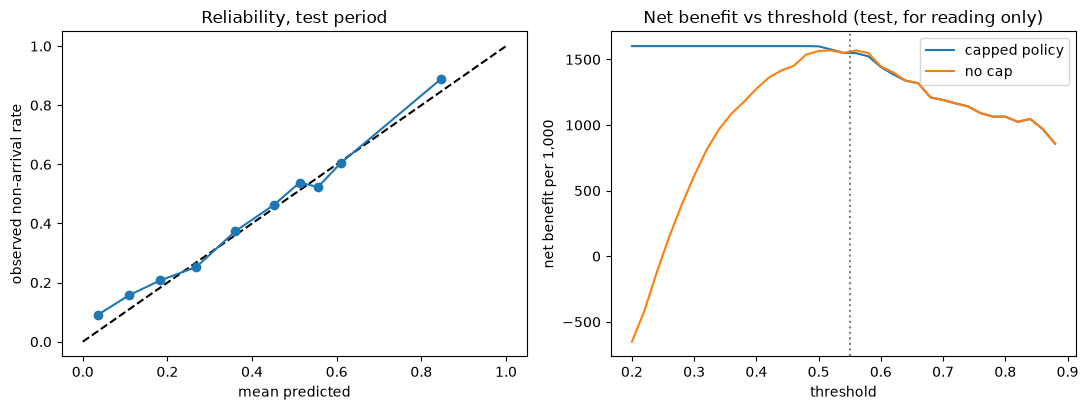


hotel
               rows  actual_rate  mean_pred  flagged  precision  recall  nb_per_1000
hotel                                                                               
City Hotel    16463        0.434      0.445    0.281      0.709   0.459     1854.917
Resort Hotel   7555        0.356      0.280    0.092      0.774   0.201      832.561

market_segment
                 rows  actual_rate  mean_pred  flagged  precision  recall  nb_per_1000
market_segment                                                                        
Corporate         640        0.242      0.185    0.072      0.848   0.252      847.656
Direct           2653        0.184      0.193    0.012      0.452   0.029      -35.809
Groups           2743        0.661      0.716    0.735      0.812   0.902     7666.788
Offline TA/TO    3843        0.354      0.323    0.265      0.748   0.559     2127.895
Online TA       13961        0.430      0.400    0.158      0.619   0.228      509.992

arrival_month
             

In [34]:
twin_free = full_report(pt, THR, subset=~tw)[0]; twin_only = full_report(pt, THR, subset=tw)[0]
print("all test rows       :", {k: round(v, 3) for k, v in rep_lr.items()})
print("twin-free test rows :", {k: round(v, 3) for k, v in twin_free.items()}, "| PR-AUC", round(average_precision_score(yt[~tw], pt[~tw]), 4))
print("profile-twin rows   :", {k: round(v, 3) for k, v in twin_only.items()}, "| PR-AUC", round(average_precision_score(yt[tw], pt[tw]), 4))
# reliability
dec = pd.qcut(pt, 10, duplicates="drop"); rel = pd.DataFrame({"p": pt, "y": yt}).groupby(dec).agg(mean_p=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
display(rel.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].plot(rel.mean_p, rel.obs, "o-"); ax[0].set_xlabel("mean predicted"); ax[0].set_ylabel("observed non-arrival rate"); ax[0].set_title("Reliability, test period")
tg = np.arange(0.2, 0.9, 0.02)
ax[1].plot(tg, [net_benefit(yt, capped_flags(pt, wt, at, t)[0]) / len(yt) * 1000 for t in tg], label="capped policy")
ax[1].plot(tg, [net_benefit(yt, pt >= t) / len(yt) * 1000 for t in tg], label="no cap"); ax[1].axvline(THR, color="grey", ls=":")
ax[1].set_xlabel("threshold"); ax[1].set_ylabel("net benefit per 1,000"); ax[1].legend(); ax[1].set_title("Net benefit vs threshold (test, for reading only)")
plt.tight_layout(); plt.savefig(FIG / "05_calibration_and_threshold.png", dpi=110); plt.show()

def slice_table(keys, name):
    r = []
    for g in np.unique(keys):
        m = keys == g
        if m.sum() < 300: continue
        rr = full_report(pt, THR, subset=m)[0]
        r.append({name: g, "rows": int(m.sum()), "actual_rate": yt[m].mean(), "mean_pred": pt[m].mean(), "flagged": rr["flagged_share"],
                  "precision": rr["precision"], "recall": rr["recall"], "nb_per_1000": rr["net_benefit_per_1000"]})
    return pd.DataFrame(r).set_index(name).round(3)
sl = {}
sl["hotel"] = slice_table(df.hotel.values[st], "hotel")
sl["market_segment"] = slice_table(df.market_segment.values[st], "market_segment")
sl["arrival_month"] = slice_table(mth, "arrival_month")
sl["lead_time_bin"] = slice_table(pd.cut(ltt, [-1, 7, 30, 90, 180, 800], labels=["0-7", "8-30", "31-90", "91-180", "181+"]).astype(str), "lead_time_bin")
for k, v in sl.items(): print("\n" + k); print(v)
pd.concat(sl, names=["slice"]).to_csv(ART / "test_slices.csv")

## 5.3 Explanations (SHAP on the logistic regression, read as association only) and fairness

,mean |SHAP| (log-odds)
agent_id,1.1824
market_segment,1.1801
customer_type,0.7586
log_lead_time,0.6241
hotel,0.5762
previous_cancellations,0.4847
total_guests,0.3553
adults,0.3185
previous_bookings_not_canceled,0.2790
reserved_room_type,0.2292


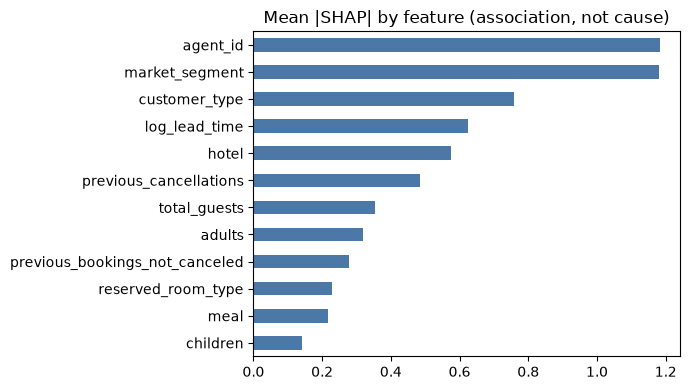

SHAP direction check: correlation of log_lead_time with its SHAP value: 1.0 | lead_time (collinear with its log): -1.0


In [35]:
import shap
pipe = model
Zbg = pipe[:-1].transform(X[S["fit"]].sample(2000, random_state=SEED)); samp_te = Xt.sample(3000, random_state=SEED)
Zte = pipe[:-1].transform(samp_te)
shv = shap.LinearExplainer(pipe.named_steps["clf"], shap.maskers.Independent(Zbg, max_samples=2000)).shap_values(Zte)
names = pipe.named_steps["pre"].get_feature_names_out()
def group_of(nm):
    if nm.startswith("num__"): return nm[5:]
    c = [c for c in hf.CAT_A if nm.startswith("cat__" + c + "_")]
    return max(c, key=len) if c else nm
grp = pd.Series([group_of(n) for n in names])
imp = pd.DataFrame(np.abs(shv), columns=names).T.groupby(grp.values).sum().T.mean().sort_values(ascending=False)
display(imp.head(12).round(4).to_frame("mean |SHAP| (log-odds)"))
fig, ax = plt.subplots(figsize=(7, 4)); imp.head(12)[::-1].plot.barh(ax=ax, color="#4C78A8"); ax.set_title("Mean |SHAP| by feature (association, not cause)"); plt.tight_layout()
plt.savefig(FIG / "05_shap.png", dpi=110); plt.show()
lt_col = list(names).index("num__lead_time"); lg_col = list(names).index("num__log_lead_time")
print("SHAP direction check: correlation of log_lead_time with its SHAP value:", round(float(np.corrcoef(Zte[:, lg_col], shv[:, lg_col])[0, 1]), 3), "| lead_time (collinear with its log):", round(float(np.corrcoef(Zte[:, lt_col], shv[:, lt_col])[0, 1]), 3))

In [36]:
# Fairness: country is Set B and is NOT a model input, but other inputs can act as proxies.
ctry = df.country.fillna("missing").values[st]
cg = np.where(np.isin(ctry, ["PRT", "GBR", "FRA", "DEU", "ESP"]), ctry, "other")
rows = []
for g in np.unique(cg):
    m = cg == g; f = f_lr[m]; ym = yt[m]
    rows.append({"country group": g, "rows": int(m.sum()), "actual_rate": ym.mean(), "mean_pred": pt[m].mean(), "flagged": f.mean(),
                 "recall": f[ym == 1].mean(), "false_positive_rate": f[ym == 0].mean(), "precision": ym[f].mean() if f.any() else np.nan})
fair = pd.DataFrame(rows).set_index("country group").round(3); display(fair); fair.to_csv(ART / "test_fairness_country.csv")
print("flagged-share ratio max/min:", round(fair.flagged.max() / fair.flagged.min(), 2), "| FPR ratio max/min:", round(fair.false_positive_rate.max() / fair.false_positive_rate.min(), 2))

,rows,actual_rate,mean_pred,flagged,recall,false_positive_rate,precision
country group,,,,,,,
DEU,1862,0.212,0.403,0.234,0.287,0.219,0.260
ESP,1467,0.389,0.348,0.127,0.208,0.075,0.640
FRA,2112,0.288,0.383,0.131,0.217,0.096,0.478
GBR,3291,0.276,0.341,0.186,0.332,0.130,0.492
PRT,7164,0.636,0.444,0.381,0.558,0.070,0.933
other,8122,0.345,0.378,0.134,0.217,0.089,0.562


flagged-share ratio max/min: 3.0 | FPR ratio max/min: 3.13


## 5.4 Sensitivity and break-even

In [37]:
sens = pd.DataFrame({f"c={c_}": {f"s={s_}": (s_ * L_LOSS * (f_lr & (yt == 1)).sum() - c_ * f_lr.sum()) / len(yt) * 1000 for s_ in (0.10, 0.25, 0.40)} for c_ in (10, 20, 40)}).round(0)
print("net benefit per 1,000 with the frozen flags, L=150:"); display(sens)
prec = rep_lr["precision"]; print("break-even save rate for the frozen policy: s* = c / (L x precision) =", round(C_COST / (L_LOSS * prec), 3))
cap_tab = pd.Series({cap: net_benefit(yt, capped_flags(pt, wt, at, THR, cap=cap)[0]) / len(yt) * 1000 for cap in (0.10, 0.15, 0.25, 0.40, 1.0)})
print("net benefit per 1,000 by weekly cap (threshold fixed):"); print(cap_tab.round(0).to_dict())
months = (raw.arrival_date.max() - raw.arrival_date.min()).days / 30.44
per_year = len(df) / months * 12
annual = rep_lr["net_benefit_per_1000"] * per_year / 1000
cost_y1 = 1800 + 120 * 12
mo_nb = {int(m_): net_benefit(yt[mth == m_], f_lr[mth == m_]) / (mth == m_).sum() * 1000 for m_ in np.unique(mth)}
print("net benefit per 1,000 by arrival month (test):", {k: round(v) for k, v in mo_nb.items()})
levels = {"test average (Apr-Aug, peak season)": rep_lr["net_benefit_per_1000"], "Monte Carlo median (B1)": float(np.median(mc)), "July-August only": net_benefit(yt[mth >= 7], f_lr[mth >= 7]) / (mth >= 7).sum() * 1000}
print(f"bookings per year ~{per_year:,.0f} | year-one cost {cost_y1:,} (development 1,800 + operating 1,440)")
for k_, v_ in levels.items():
    a_ = v_ * per_year / 1000
    print(f"  {k_}: net benefit/1000 {v_:.0f} -> annual {a_:,.0f}" + (f" | payback {cost_y1 / a_ * 12:.1f} months" if a_ > 0 else " | never pays back"))
json.dump({"criteria": crit.astype(str).to_dict("records"), "summary": summary.round(4).to_dict(), "twin_free": {k: float(v) for k, v in twin_free.items()},
           "d5_test": {"A": prA, "A_plus_B": prAB}, "per_year": per_year, "annual_nb": annual, "cap_table": cap_tab.to_dict()},
          open(ART / "metrics_phase5.json", "w"), indent=1, default=str)

net benefit per 1,000 with the frozen flags, L=150:


,c=10,c=20,c=40
s=0.1,170.0,-2046.0,-6479.0
s=0.25,3750.0,1533.0,-2899.0
s=0.4,7329.0,5113.0,680.0


break-even save rate for the frozen policy: s* = c / (L x precision) = 0.186
net benefit per 1,000 by weekly cap (threshold fixed):
{0.1: 855.0, 0.15: 1207.0, 0.25: 1533.0, 0.4: 1526.0, 1.0: 1526.0}
net benefit per 1,000 by arrival month (test): {4: 3415, 5: 2781, 6: 2415, 7: 9, 8: -134}
bookings per year ~54,980 | year-one cost 3,240 (development 1,800 + operating 1,440)
  test average (Apr-Aug, peak season): net benefit/1000 1533 -> annual 84,303 | payback 0.5 months
  Monte Carlo median (B1): net benefit/1000 214 -> annual 11,788 | payback 3.3 months
  July-August only: net benefit/1000 -60 -> annual -3,277 | never pays back


# Phase 6: Deployment
## 6.1 Plan deployment: the scoring path is tested against the notebook
The Streamlit app (`deployment/app.py`) and the batch path both call `deployment/scoring.py`. The check below loads the deployed model files from disk, scores the raw test rows, and requires the same probabilities and flags as Phase 5.

In [38]:
if (DEP / "scoring.py").exists():
    import importlib, scoring, monitor
    importlib.reload(scoring)
    champion, challenger = scoring.load_models(); policy = scoring.load_policy()
    raw_test = df.loc[S["test"], hf.RAW_A_COLS]
    out = scoring.score_frame(raw_test, champion, challenger, policy, apply_cap=True)
    assert np.allclose(out.p_champion.values, pt, atol=1e-10), "deployed champion differs from the Phase 5 predictions"
    assert np.allclose(out.p_challenger.values, pt2, atol=1e-10), "deployed challenger differs from the Phase 5 predictions"
    assert (out.flag_outreach.values == f_lr).all(), "deployed capped flags differ from the Phase 5 flags"
    print("deployment check passed: probabilities and capped flags match Phase 5 on", len(out), "test bookings")
    sample = df.loc[S["test"], hf.RAW_A_COLS].sample(200, random_state=SEED).sort_values(["arrival_date_year", "arrival_date_week_number"])
    sample.to_csv(DEP / "sample_bookings.csv", index=False)
    print("model files:", {f.name: f"{f.stat().st_size / 1024:.0f} KB" for f in DEP.glob('*.joblib')})
else:
    print("Deployment files are in the repository (deployment/); clone it to run this check.")

deployment check passed: probabilities and capped flags match Phase 5 on 24018 test bookings
model files: {'model.joblib': '6 KB', 'model_challenger.joblib': '216 KB'}


## 6.2 Plan monitoring and maintenance
The monitoring code (`deployment/monitor.py`) is demonstrated on the test period, treated as if it were the live stream against the training distribution.

In [39]:
if (DEP / "scoring.py").exists():
    fit_x, test_x = df.loc[S["fit"]], df.loc[S["test"]]
    psis = {"lead_time": monitor.psi(fit_x.lead_time, test_x.lead_time), "market_segment": monitor.psi(fit_x.market_segment, test_x.market_segment),
            "hotel": monitor.psi(fit_x.hotel, test_x.hotel), "customer_type": monitor.psi(fit_x.customer_type, test_x.customer_type),
            "total nights": monitor.psi(fit_x.stays_in_week_nights + fit_x.stays_in_weekend_nights, test_x.stays_in_week_nights + test_x.stays_in_weekend_nights)}
    print({k: round(v, 3) for k, v in psis.items()})
    wk_df = pd.DataFrame({"week": wt, "p": pt, "y": yt, "flag": f_lr})
    weekly = monitor.weekly_report(wk_df)
    display(weekly.round(3).head(8))
    cg_df = pd.DataFrame({"country": cg, "y": yt, "flag": f_lr}); crates = monitor.group_rates(cg_df, "country")
    print("false-positive rate by country group:", crates.false_positive_rate.round(3).to_dict(), "| ratio", round(monitor.fpr_ratio(crates), 2))
    print("alerts the monitor would raise on the test stream:")
    for m in monitor.alerts(psis, weekly, country_rates=crates): print(" -", m)
    # pilot logic check: Groups never take a weekly slot, arms are balanced and stable
    elig = (df.loc[S["test"], "market_segment"] != "Groups").values
    o2 = scoring.score_frame(raw_test, champion, challenger, policy, apply_cap=True, eligible=elig)
    pc = scoring.pilot_columns(raw_test, o2.flag_outreach.values, above=o2.above_threshold.values)
    fl_ok = pc[pc.pilot_arm != ""]; yy = pd.Series(yt, index=pc.index)
    print("pilot: eligible flagged", len(fl_ok), "| outreach arm share", round((fl_ok.pilot_arm == "outreach").mean(), 3),
          "| precision among eligible flagged", round(float(yy[fl_ok.index].mean()), 3),
          "| Groups above threshold but excluded:", int(pc.action.str.startswith("above threshold but Group").sum()),
          "| Group bookings flagged:", int((o2.flag_outreach.values & ~elig).sum()),
          "| stable on repeat:", bool((scoring.pilot_columns(raw_test, o2.flag_outreach.values, above=o2.above_threshold.values).pilot_arm == pc.pilot_arm).all()))
    print("pilot flagged per month:", round(len(fl_ok) / ((df.arrival_date[S["test"]].max() - df.arrival_date[S["test"]].min()).days / 30.44)))

{'lead_time': 0.171, 'market_segment': 0.137, 'hotel': 0.004, 'customer_type': 0.133, 'total nights': 0.047}


,bookings,expected_non_arrivals,actual_non_arrivals,flagged,flagged_precision,aggregate_error,flagged_share
week,,,,,,,
201716,392,176.952,178,98,0.949,0.006,0.250
201717,1449,628.993,668,362,0.884,0.058,0.250
201718,1470,622.175,692,367,0.853,0.101,0.250
201719,1298,466.022,478,286,0.745,0.025,0.220
201720,1511,719.812,763,377,0.992,0.057,0.250
201721,1472,595.347,574,368,0.688,0.037,0.250
201722,1403,625.175,624,350,0.883,0.002,0.249
201723,1374,555.326,608,343,0.878,0.087,0.250


false-positive rate by country group: {'DEU': 0.219, 'ESP': 0.075, 'FRA': 0.096, 'GBR': 0.13, 'PRT': 0.07, 'other': 0.089} | ratio 3.12
alerts the monitor would raise on the test stream:
 - PSI lead_time = 0.17 (> 0.1): watch
 - PSI market_segment = 0.14 (> 0.1): watch
 - PSI customer_type = 0.13 (> 0.1): watch
 - flagged precision below 0.60 for 3 weeks in a row: pause outreach and review (aggregate error alone would not catch this: totals can stay right while the flagged set gets worse)
 - false-positive-rate ratio across country groups is 3.1 (> 1.5): review proxies such as agent_id


pilot: eligible flagged 4229 | outreach arm share 0.517 | precision among eligible flagged 0.637 | Groups above threshold but excluded: 2042 | Group bookings flagged: 0 | stable on repeat: True
pilot flagged per month: 983


## 6.3 Final summary of the notebook

In [40]:
print("Chosen model :", frozen["chosen_model"], "| threshold", THR, "| weekly cap", CAP)
print("Test (Apr 22 - Aug 31 2017):", {k: round(float(v), 3) for k, v in rep_lr.items()})
print("Criteria passed/failed:", crit["pass"].value_counts(dropna=False).to_dict())
print("Artifacts written to:", ART)

Chosen model : Logistic regression | threshold 0.55 | weekly cap 0.25
Test (Apr 22 - Aug 31 2017): {'rows': 24018.0, 'flagged_share': 0.222, 'precision': 0.718, 'recall': 0.388, 'net_benefit_per_1000': 1533.329, 'cap_binds_share_of_weeks': 0.65}
Criteria passed/failed: {np.True_: 5, np.False_: 4, None: 1}
Artifacts written to: /Users/oleg/Documents/Coding/SJSU/Data-Mining/Data-Science-Methodologies/01_CRISP-DM_Hotel-Cancellation/artifacts
